<a href="https://colab.research.google.com/github/syifaymd/Tugas-Kelompok-7/blob/main/Analisis_SARIMA_SARIMAX_Sulawesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Peramalan Produksi Padi Pulau Sulawesi dengan SARIMA dan SARIMAX

Notebook ini menjalankan **10 tahapan analisis** sesuai urutan penelitian:

1. Exploratory Data Analysis (EDA)
2. Split data Hold-Out
3. Uji stasioneritas: Box-Cox, ADF, ACF, dan PACF
4. Penanganan stasioneritas: differencing dan pemeriksaan ulang ACF/PACF
5. Identifikasi model SARIMA dan SARIMAX
6. Pendugaan parameter dengan Maximum Likelihood Estimation (MLE)
7. Diagnostik residual: Ljung-Box, Jarque-Bera, dan ARCH-LM beserta arahan penanganan
8. Pemeriksaan overfitting
9. Evaluasi dan perbandingan SARIMA–SARIMAX
10. Forecasting dan plot aktual vs prediksi

**Cakupan:** enam provinsi di Pulau Sulawesi. Setiap provinsi dimodelkan sebagai deret waktu bulanan yang terpisah.  
**Variabel:** `Y` = target produksi padi; `X1` dan `X2` = variabel eksogen SARIMAX.  
**Periode musiman:** 12 bulan.

Jalankan seluruh sel secara berurutan. Saat diminta, unggah file Excel data padi yang memiliki kolom `Provinsi`, `Tahun`, `Bulan`, `Y`, `X1`, dan `X2`.

## Persiapan: Import library dan konfigurasi

In [ ]:

# ============================================================
# 0. INSTALASI LIBRARY DAN KONFIGURASI PENELITIAN
# SARIMA DAN SARIMAX - ENAM PROVINSI DI PULAU SULAWESI
# ============================================================

!pip -q install openpyxl statsmodels scipy scikit-learn seaborn

import warnings
import itertools
import os

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from scipy import stats
from scipy.stats import chi2
from scipy.special import inv_boxcox

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from IPython.display import display

# ============================================================
# 1. KONFIGURASI GRAFIK STATIS UNTUK JURNAL
# ============================================================

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "savefig.bbox": "tight"
})

# Folder penyimpanan grafik
FOLDER_GRAFIK = "Grafik_Jurnal_Sulawesi"
os.makedirs(FOLDER_GRAFIK, exist_ok=True)

# Fungsi menyimpan grafik
def simpan_grafik(fig, nama_file):

    nama_file = (
        str(nama_file)
        .replace(" ", "_")
        .replace("/", "-")
    )

    fig.savefig(
        f"{FOLDER_GRAFIK}/{nama_file}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        f"{FOLDER_GRAFIK}/{nama_file}.pdf",
        bbox_inches="tight"
    )

# ============================================================
# 2. KONFIGURASI PENELITIAN
# ============================================================

PROVINSI_SULAWESI = [
    "SULAWESI UTARA",
    "GORONTALO",
    "SULAWESI TENGAH",
    "SULAWESI BARAT",
    "SULAWESI SELATAN",
    "SULAWESI TENGGARA"
]

# Variabel penelitian
TARGET = "Y"           # Produksi padi
EXOG = ["X1", "X2"]    # Luas panen, curah hujan

# Periode musiman
S = 12

# Pembagian data
HORIZON_TEST = 20

# Peramalan masa depan
HORIZON_FORECAST = 12

# Tingkat signifikansi
ALPHA = 0.05

# Kandidat orde SARIMA/SARIMAX
P_VALUES = [0, 1, 2]
Q_VALUES = [0, 1, 2]

SP_VALUES = [0, 1]
SQ_VALUES = [0, 1]

# ============================================================
# 3. RINGKASAN KONFIGURASI
# ============================================================

print("=" * 65)
print("KONFIGURASI PENELITIAN SARIMA DAN SARIMAX")
print("=" * 65)

print("Jumlah provinsi      :", len(PROVINSI_SULAWESI))
print("Variabel target      :", TARGET)
print("Variabel eksogen     :", EXOG)
print("Periode musiman      :", S)
print("Data testing         :", HORIZON_TEST, "bulan")
print("Forecast masa depan  :", HORIZON_FORECAST, "bulan")
print("Signifikansi         :", ALPHA)
print("Grafik               : Statis (Matplotlib/Seaborn)")
print("Resolusi             : 300 dpi")
print("Folder grafik        :", FOLDER_GRAFIK)

print("\nKonfigurasi siap.")


KONFIGURASI PENELITIAN SARIMA DAN SARIMAX
Jumlah provinsi      : 6
Variabel target      : Y
Variabel eksogen     : ['X1', 'X2']
Periode musiman      : 12
Data testing         : 20 bulan
Forecast masa depan  : 12 bulan
Signifikansi         : 0.05
Grafik               : Statis (Matplotlib/Seaborn)
Resolusi             : 300 dpi
Folder grafik        : Grafik_Jurnal_Sulawesi

Konfigurasi siap.


## Membaca dan menyiapkan dataset

In [ ]:
from google.colab import files
uploaded = files.upload()
nama_file = next(iter(uploaded))
raw = pd.read_excel(nama_file)

# Samakan nama kolom jika file menggunakan nama lama
raw = raw.rename(columns={
    "X": "X1",
    "Curah_Hujan_mm": "X2"
})
raw.columns = raw.columns.astype(str).str.strip()

kolom_wajib = ["Provinsi", "Tahun", "Bulan", "Y", "X1", "X2"]
kolom_hilang = [c for c in kolom_wajib if c not in raw.columns]
if kolom_hilang:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_hilang}")

bulan_map = {
    "januari": 1, "februari": 2, "maret": 3, "april": 4,
    "mei": 5, "juni": 6, "juli": 7, "agustus": 8,
    "september": 9, "oktober": 10, "nopember": 11,
    "november": 11, "desember": 12
}

df = raw.copy()
df["Provinsi"] = df["Provinsi"].astype(str).str.strip().str.upper()
df["bulan_angka"] = df["Bulan"].astype(str).str.strip().str.lower().map(bulan_map)

if df["bulan_angka"].isna().any():
    raise ValueError("Terdapat nama bulan yang tidak dikenali.")

df["Tanggal"] = pd.to_datetime({
    "year": df["Tahun"].astype(int),
    "month": df["bulan_angka"].astype(int),
    "day": 1
})

for c in ["Y", "X1", "X2"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

data = df[df["Provinsi"].isin(PROVINSI_SULAWESI)].copy()
prov_tidak_ada = sorted(set(PROVINSI_SULAWESI) - set(data["Provinsi"].unique()))
if prov_tidak_ada:
    raise ValueError(f"Provinsi tidak ditemukan dalam dataset: {prov_tidak_ada}")

# Pastikan satu observasi per provinsi-bulan
duplikat = data.duplicated(["Provinsi", "Tanggal"], keep=False)
if duplikat.any():
    raise ValueError("Ada lebih dari satu baris untuk provinsi dan bulan yang sama. Periksa data sumber.")

# Bentuk deret bulanan terpisah untuk masing-masing provinsi
seri = {}
for prov in PROVINSI_SULAWESI:
    temp = data[data["Provinsi"] == prov].sort_values("Tanggal").set_index("Tanggal")
    temp = temp[["Y", "X1", "X2"]].asfreq("MS")
    if temp.isna().any().any():
        print(f"PERINGATAN: terdapat nilai kosong pada {prov}.")
    seri[prov] = temp

print("Jumlah observasi per provinsi:")
display(pd.DataFrame({
    "Provinsi": PROVINSI_SULAWESI,
    "Jumlah observasi": [len(seri[p]) for p in PROVINSI_SULAWESI],
    "Awal": [seri[p].index.min() for p in PROVINSI_SULAWESI],
    "Akhir": [seri[p].index.max() for p in PROVINSI_SULAWESI]
}))

print("Missing value per provinsi:")
display(pd.DataFrame({
    p: seri[p].isna().sum() for p in PROVINSI_SULAWESI
}).T)

Saving Data_Padi.xlsx to Data_Padi.xlsx
Jumlah observasi per provinsi:


,Provinsi,Jumlah observasi,Awal,Akhir
0,SULAWESI UTARA,104,2018-01-01,2026-08-01
1,GORONTALO,104,2018-01-01,2026-08-01
2,SULAWESI TENGAH,104,2018-01-01,2026-08-01
3,SULAWESI BARAT,104,2018-01-01,2026-08-01
4,SULAWESI SELATAN,104,2018-01-01,2026-08-01
5,SULAWESI TENGGARA,104,2018-01-01,2026-08-01


Missing value per provinsi:


,Y,X1,X2
SULAWESI UTARA,0,0,0
GORONTALO,0,0,0
SULAWESI TENGAH,0,0,0
SULAWESI BARAT,0,0,0
SULAWESI SELATAN,0,0,0
SULAWESI TENGGARA,0,0,0


In [ ]:

# ============================================================
# PENYIMPANAN OTOMATIS SELURUH GRAFIK
# TANPA GOOGLE DRIVE
# ============================================================

import os
import matplotlib.pyplot as plt

FOLDER_UTAMA = "/content/Hasil_Analisis_Padi_Sulawesi"
FOLDER_GRAFIK = os.path.join(FOLDER_UTAMA, "Grafik_Jurnal")

os.makedirs(FOLDER_GRAFIK, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10
})

# Hindari pembungkusan berulang jika sel dijalankan ulang
if not hasattr(plt, "_show_asli_jurnal"):
    plt._show_asli_jurnal = plt.show

nomor_grafik = 0

def simpan_otomatis(*args, **kwargs):
    global nomor_grafik

    for nomor_fig in plt.get_fignums():
        fig = plt.figure(nomor_fig)
        nomor_grafik += 1

        nama = f"Grafik_{nomor_grafik:03d}"

        fig.savefig(
            os.path.join(FOLDER_GRAFIK, nama + ".png"),
            dpi=300,
            bbox_inches="tight"
        )

        fig.savefig(
            os.path.join(FOLDER_GRAFIK, nama + ".pdf"),
            bbox_inches="tight"
        )

    plt._show_asli_jurnal(*args, **kwargs)

plt.show = simpan_otomatis

print("Penyimpanan otomatis grafik aktif.")


Penyimpanan otomatis grafik aktif.


# 1. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami karakteristik Y, X1, dan X2, memeriksa kelengkapan data, serta melihat tren dan pola musiman. Visualisasi menggunakan Plotly agar grafik dapat di-hover, di-zoom, dan dipilih rentang waktunya. Grafik EDA menggunakan keseluruhan periode sebagai eksplorasi deskriptif; parameter transformasi dan model selanjutnya hanya dipelajari dari data training.

STATISTIK DESKRIPTIF: SULAWESI UTARA


,count,mean,std,min,25%,50%,75%,max
Y,104.0,22035.605962,5806.937524,11720.650000,18108.467500,21593.125000,25201.112500,41605.090000
X1,104.0,5046.756810,1286.650613,2697.840000,4097.275000,4904.785000,5801.870000,9161.010000
X2,104.0,214.797598,96.480101,15.978765,150.704254,216.139727,279.784963,515.516143


STATISTIK DESKRIPTIF: GORONTALO


,count,mean,std,min,25%,50%,75%,max
Y,104.0,21032.537596,12097.834436,2264.040000,12969.10250,18583.150000,26251.350000,63337.530000
X1,104.0,4228.846583,2304.697044,490.580000,2573.20500,3716.300000,5363.055930,11486.009036
X2,104.0,159.037696,66.472173,4.587938,121.96442,158.248648,205.630116,307.400811


STATISTIK DESKRIPTIF: SULAWESI TENGAH


,count,mean,std,min,25%,50%,75%,max
Y,104.0,69444.828558,31358.539126,17116.560000,45060.220000,68663.220000,91472.222500,155731.370000
X1,104.0,15195.647104,6908.529126,3875.010000,9624.892500,14914.280360,20275.927500,32408.400000
X2,104.0,198.321345,79.917682,29.264843,140.361271,193.678771,236.362944,416.770612


... (2 outputs left out)

STATISTIK DESKRIPTIF: SULAWESI SELATAN


,count,mean,std,min,25%,50%,75%,max
Y,104.0,431343.332212,302973.507884,23784.320000,157000.722500,380873.09000,671783.582500,1.163518e+06
X1,104.0,84898.217456,60134.294625,4617.670000,32061.871297,67517.25000,134644.175000,2.198669e+05
X2,104.0,249.932940,100.679195,35.708017,200.803246,262.77994,314.912266,4.420533e+02


STATISTIK DESKRIPTIF: SULAWESI TENGGARA


,count,mean,std,min,25%,50%,75%,max
Y,104.0,45303.250865,23495.193985,4565.530000,29174.200000,40757.140000,57303.305000,119215.320000
X1,104.0,10883.309781,5681.177726,1115.570000,6797.851367,9626.970000,13516.895000,26160.560000
X2,104.0,213.361145,96.740802,30.626498,155.279063,229.118403,275.584203,419.121114


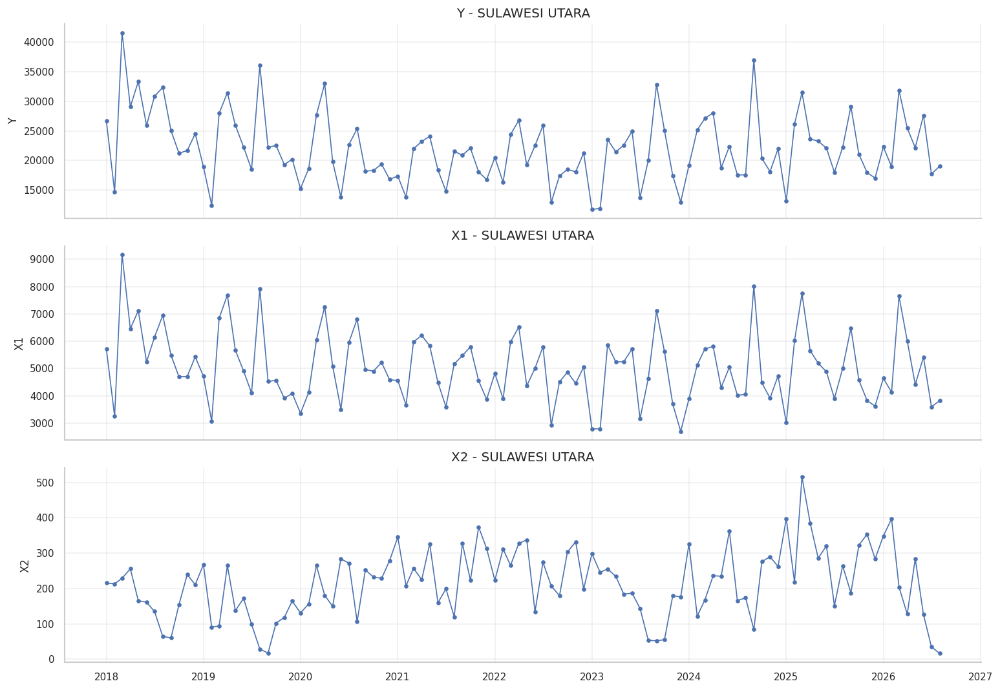

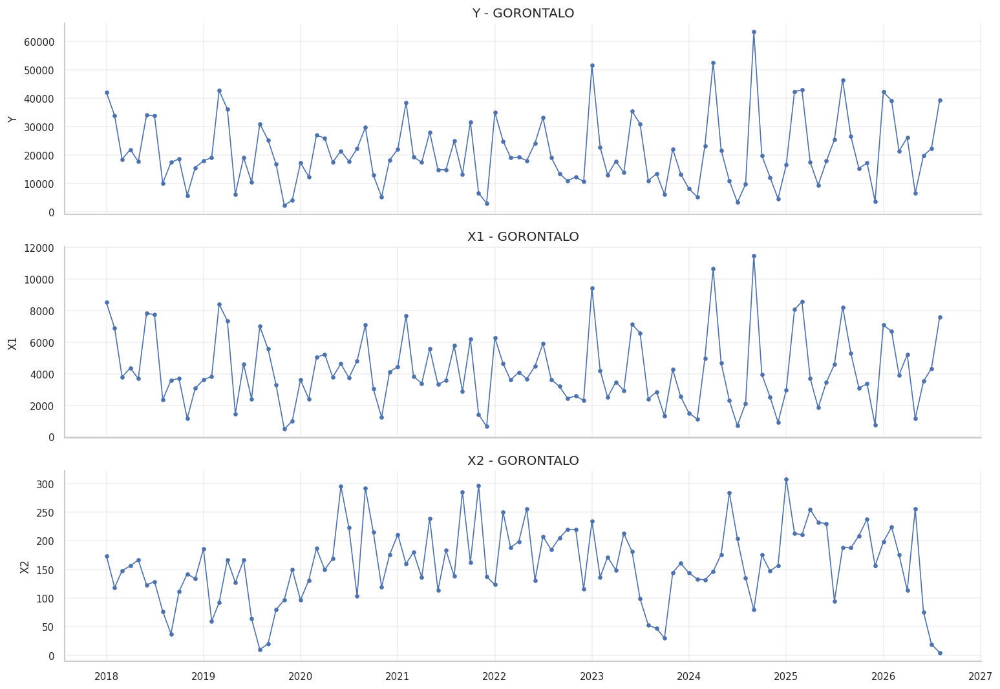

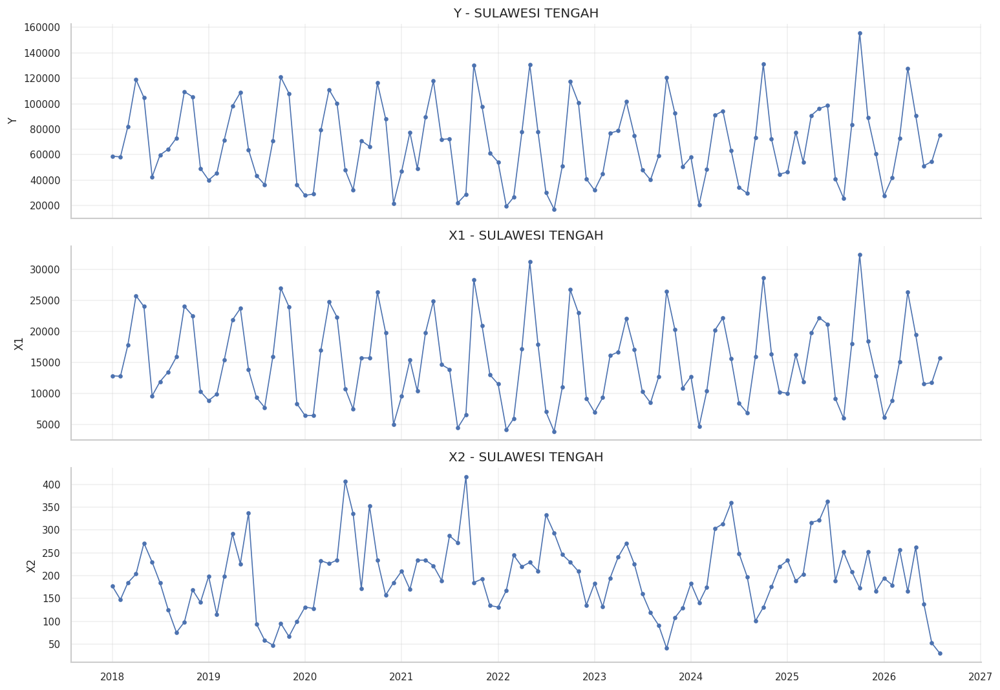

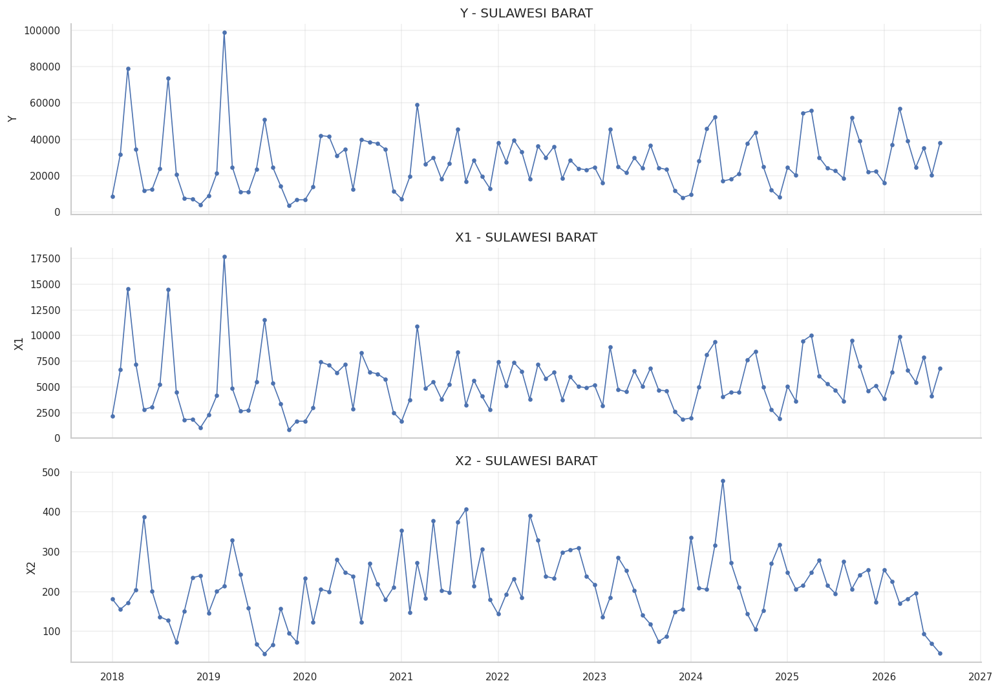

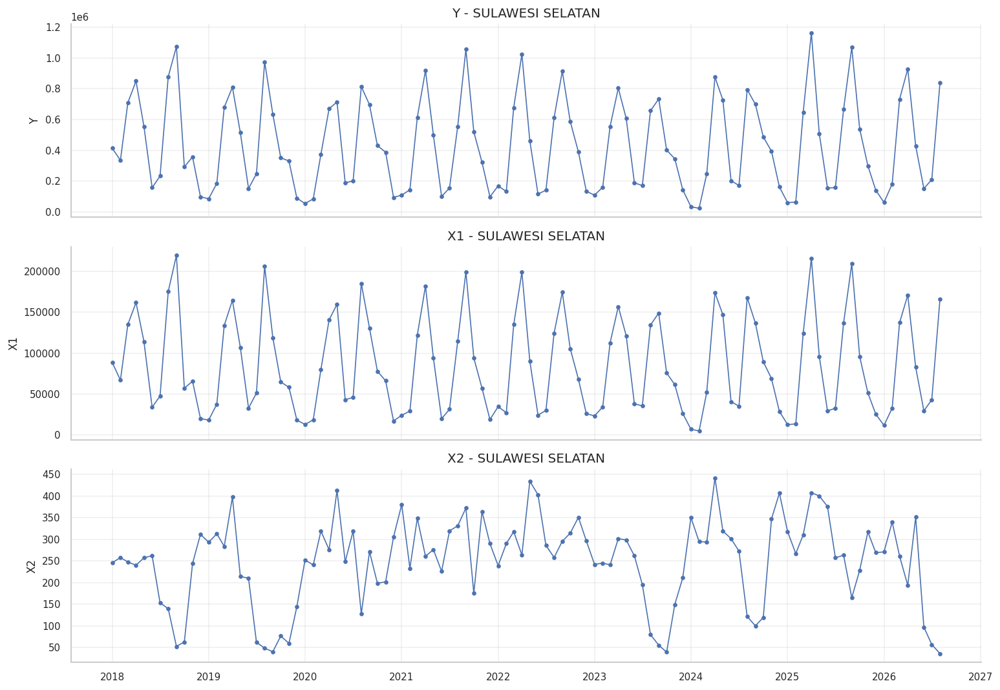

...

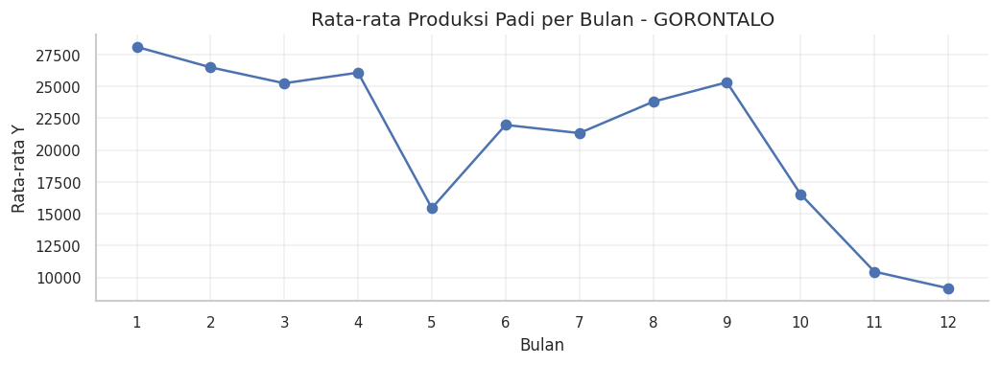

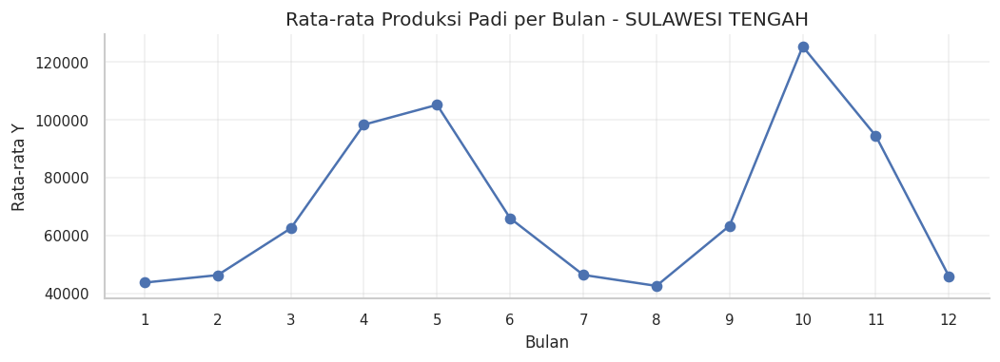

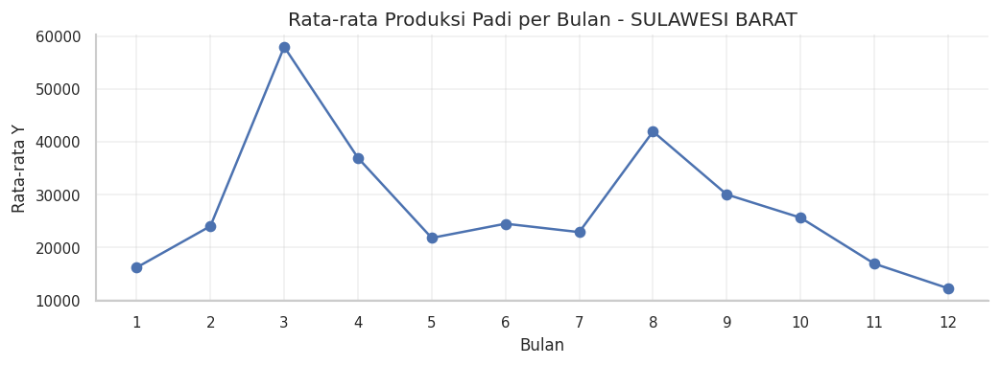

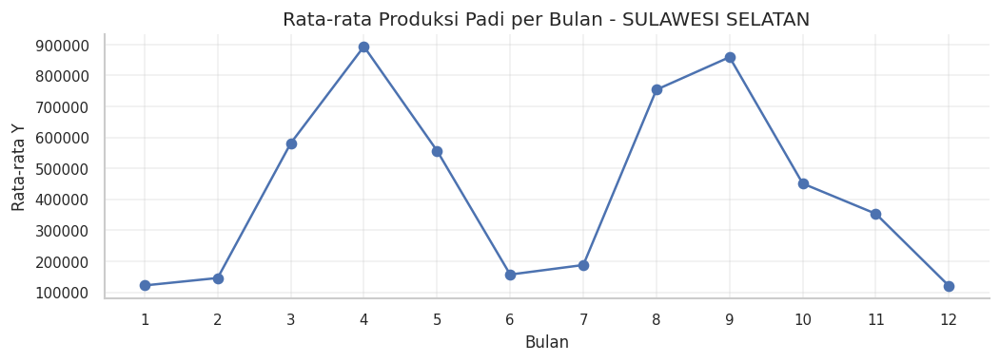

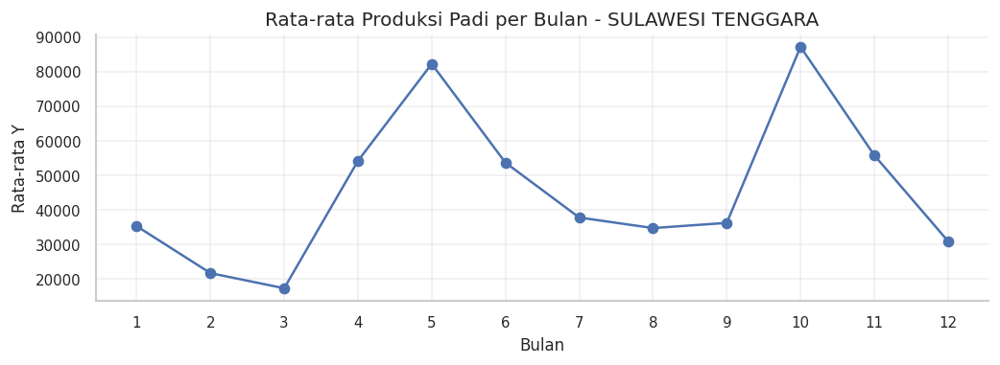

In [ ]:
# 1.1 Statistik deskriptif dan kualitas data
for prov in PROVINSI_SULAWESI:
    print(f"STATISTIK DESKRIPTIF: {prov}")
    display(seri[prov][["Y", "X1", "X2"]].describe().T)

# 1.2 Plot deret waktu Y, X1, dan X2 untuk setiap provinsi
for prov in PROVINSI_SULAWESI:
    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    for ax, kolom in zip(axes, ["Y", "X1", "X2"]):
        ax.plot(seri[prov].index, seri[prov][kolom], marker=".", linewidth=1)
        ax.set_title(f"{kolom} - {prov}")
        ax.set_ylabel(kolom)
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

# 1.3 Boxplot per provinsi untuk melihat sebaran dan pencilan
for kolom in ["Y", "X1", "X2"]:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=data, x="Provinsi", y=kolom)
    plt.title(f"Sebaran {kolom} pada Enam Provinsi Sulawesi")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# 1.4 Pola bulanan rata-rata Y
for prov in PROVINSI_SULAWESI:
    bulanan = seri[prov]["Y"].groupby(seri[prov].index.month).mean()
    plt.figure(figsize=(10, 3))
    plt.plot(bulanan.index, bulanan.values, marker="o")
    plt.xticks(range(1, 13))
    plt.title(f"Rata-rata Produksi Padi per Bulan - {prov}")
    plt.xlabel("Bulan")
    plt.ylabel("Rata-rata Y")
    plt.grid(alpha=.3)
    plt.show()

# 2. Split Data Hold-Out

Data dibagi secara kronologis dengan proporsi 80% training dan 20% testing untuk setiap provinsi. Data tidak diacak karena urutan waktu harus dipertahankan. Data testing hanya digunakan untuk evaluasi, bukan untuk menentukan transformasi atau parameter model.

PEMBAGIAN DATA TRAINING DAN TESTING
Testing: 20 bulan terakhir


,Provinsi,N total,N training,N testing,Awal training,Akhir training,Awal testing,Akhir testing
0,SULAWESI UTARA,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01
1,GORONTALO,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01
2,SULAWESI TENGAH,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01
3,SULAWESI BARAT,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01
4,SULAWESI SELATAN,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01
5,SULAWESI TENGGARA,104,84,20,2018-01-01,2024-12-01,2025-01-01,2026-08-01


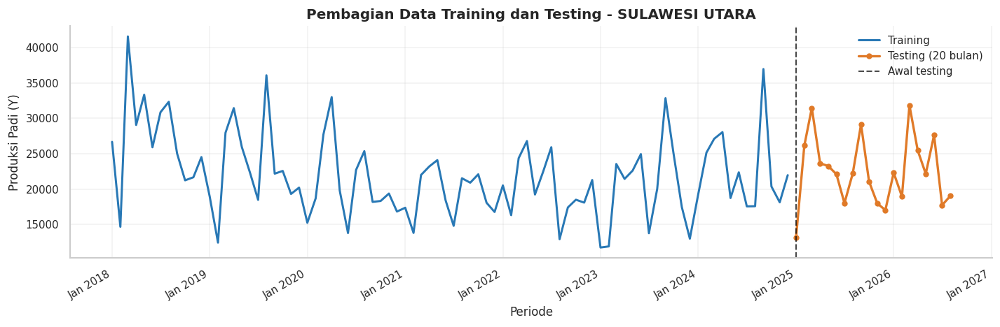

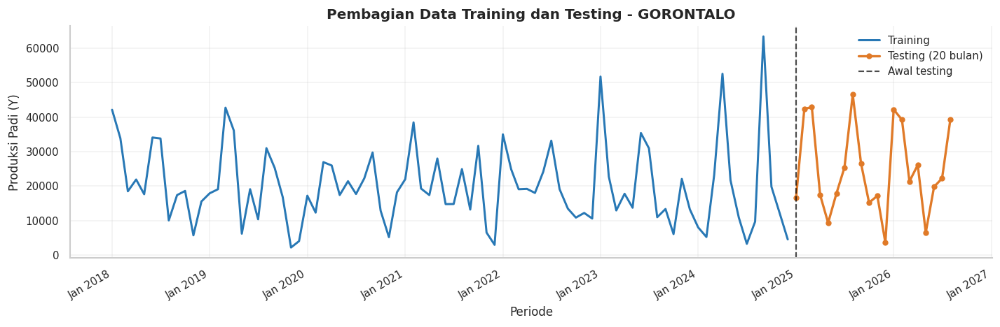

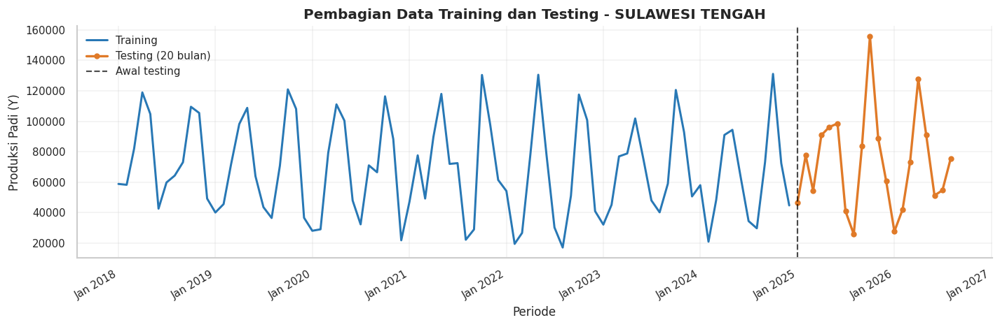

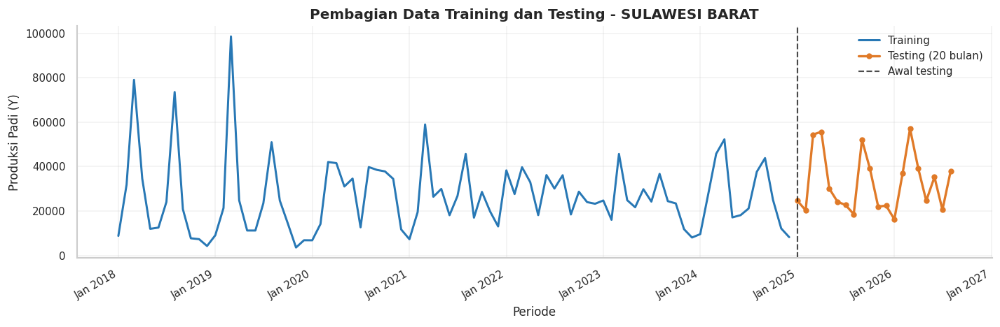

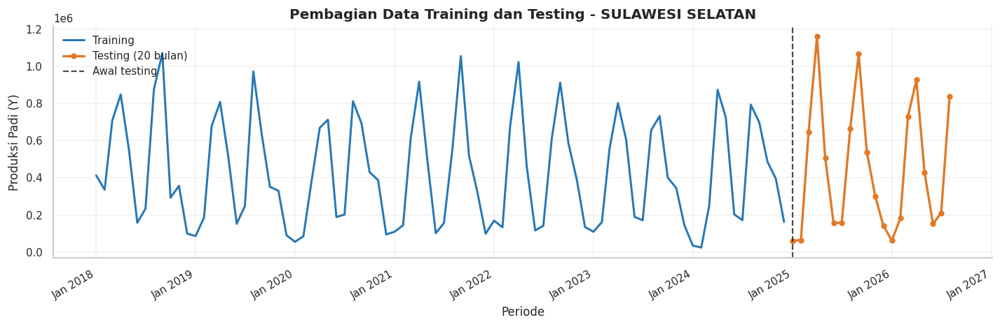

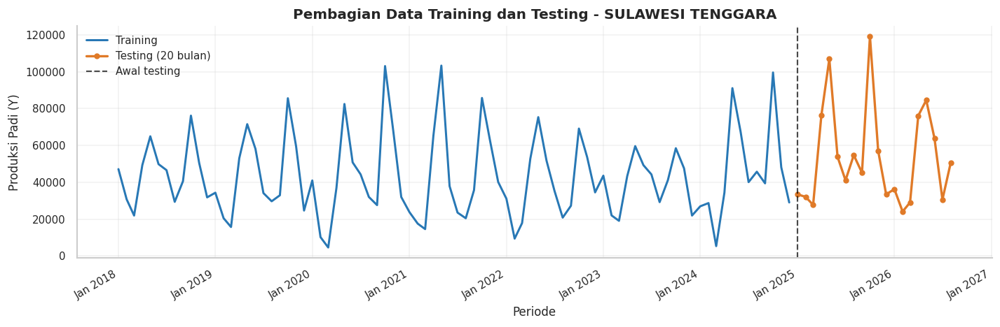

In [ ]:

# ============================================================
# PEMBAGIAN DATA TRAINING DAN TESTING
# TESTING = 20 BULAN TERAKHIR
# TRAINING = SELURUH DATA SEBELUM TESTING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

HORIZON_TEST = 20

train_test = {}
split_rows = []

for prov in PROVINSI_SULAWESI:

    temp = seri[prov].copy().sort_index()

    # Periksa data kosong
    if temp.isna().any().any():
        raise ValueError(
            f"Terdapat data kosong pada {prov}."
        )

    n = len(temp)

    # Minimal 36 bulan training + 20 bulan testing
    if n < 56:
        raise ValueError(
            f"Data {prov} tidak mencukupi. "
            f"Minimal diperlukan 56 observasi, "
            f"tersedia {n} observasi."
        )

    # 20 observasi terakhir sebagai testing
    train = temp.iloc[:-HORIZON_TEST].copy()
    test = temp.iloc[-HORIZON_TEST:].copy()

    train_test[prov] = {
        "train": train,
        "test": test
    }

    split_rows.append({
        "Provinsi": prov,
        "N total": n,
        "N training": len(train),
        "N testing": len(test),
        "Awal training": train.index.min(),
        "Akhir training": train.index.max(),
        "Awal testing": test.index.min(),
        "Akhir testing": test.index.max()
    })

# ============================================================
# TABEL PEMBAGIAN DATA
# ============================================================

tabel_split = pd.DataFrame(split_rows)

print("=" * 65)
print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("Testing: 20 bulan terakhir")
print("=" * 65)

display(tabel_split)

# ============================================================
# VISUALISASI STATIS TRAINING VS TESTING
# ============================================================

for prov in PROVINSI_SULAWESI:

    tr = train_test[prov]["train"]
    te = train_test[prov]["test"]

    fig, ax = plt.subplots(figsize=(12, 4))

    # Data training
    ax.plot(
        tr.index,
        tr["Y"],
        label="Training",
        color="#2878B5",
        linewidth=1.8
    )

    # Data testing
    ax.plot(
        te.index,
        te["Y"],
        label="Testing (20 bulan)",
        color="#E07A28",
        linewidth=2,
        marker="o",
        markersize=4
    )

    # Garis pemisah training dan testing
    ax.axvline(
        te.index[0],
        color="black",
        linestyle="--",
        linewidth=1.3,
        alpha=0.7,
        label="Awal testing"
    )

    ax.set_title(
        f"Pembagian Data Training dan Testing - {prov}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Periode")
    ax.set_ylabel("Produksi Padi (Y)")

    # Format tanggal
    ax.xaxis.set_major_locator(
        mdates.AutoDateLocator()
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %Y")
    )

    ax.legend(
        loc="best",
        frameon=False
    )

    ax.grid(alpha=0.25)

    fig.autofmt_xdate()
    fig.tight_layout()

    plt.show()
    plt.close(fig)


# 3. Uji Stasioneritas: Box-Cox, ADF, ACF, dan PACF

**Box-Cox** digunakan untuk membantu menstabilkan varians, bukan sebagai uji stasioneritas rataan. Transformasi dan nilai lambda dihitung hanya dari data training. Selanjutnya ADF menguji stasioneritas rataan. ACF/PACF ditampilkan untuk membantu identifikasi pola. Grafik profile log-likelihood Box-Cox juga ditampilkan untuk setiap provinsi, menyerupai contoh yang dilampirkan.

3.1 HASIL ESTIMASI DAN TRANSFORMASI BOX-COX


,Provinsi,Lambda MLE,CI Bawah 95%,CI Atas 95%,Lambda = 1 dalam CI,Lambda Digunakan,Shift,Transformasi Diterapkan
0,SULAWESI UTARA,-0.02354,-0.69726,0.64558,Tidak,-0.02354,0.0,Ya
1,GORONTALO,0.38256,0.11366,0.66053,Tidak,0.38256,0.0,Ya
2,SULAWESI TENGAH,0.49350,0.06664,0.93902,Tidak,0.49350,0.0,Ya
3,SULAWESI BARAT,0.23421,-0.04286,0.51278,Tidak,0.23421,0.0,Ya
4,SULAWESI SELATAN,0.35978,0.09950,0.63950,Tidak,0.35978,0.0,Ya
5,SULAWESI TENGGARA,0.46437,0.17927,0.77226,Tidak,0.46437,0.0,Ya


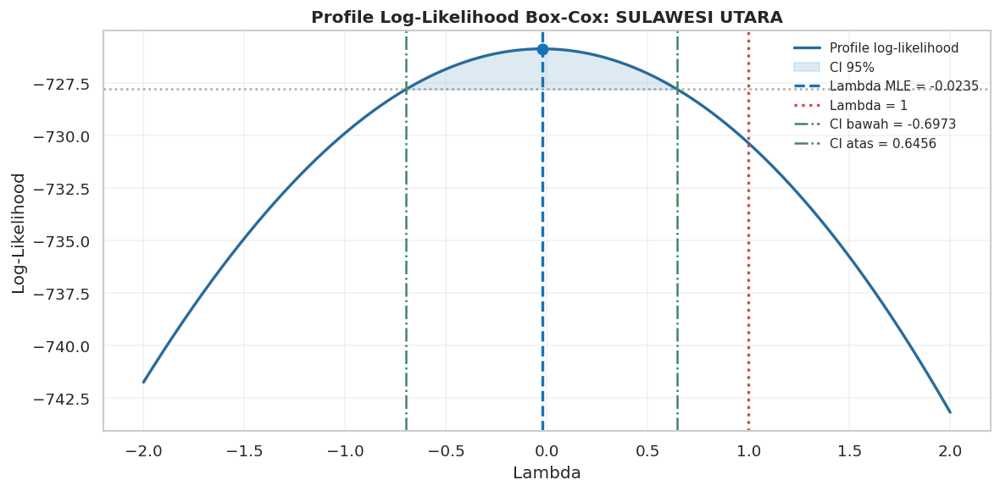

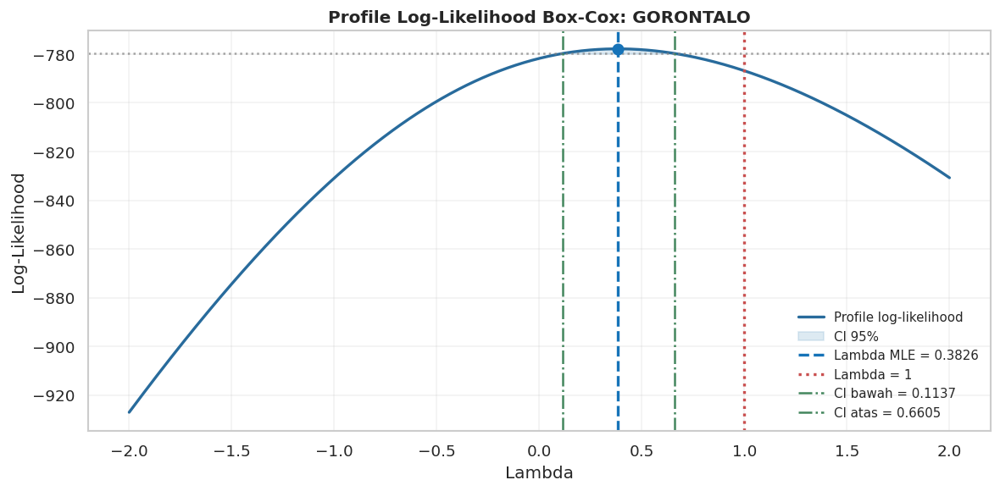

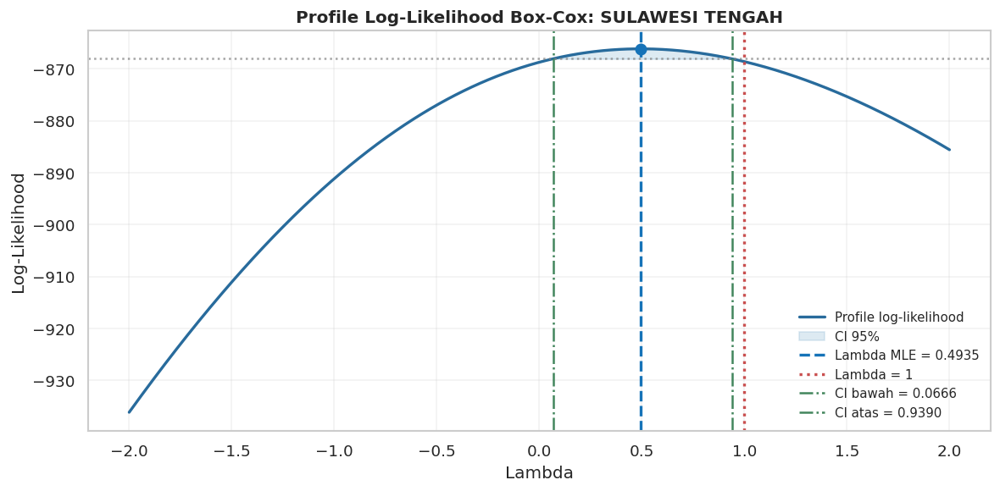

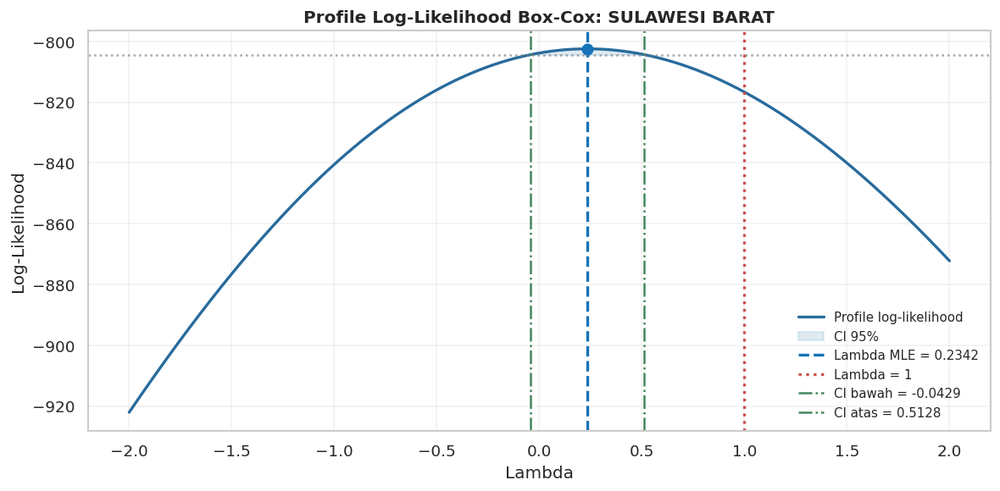

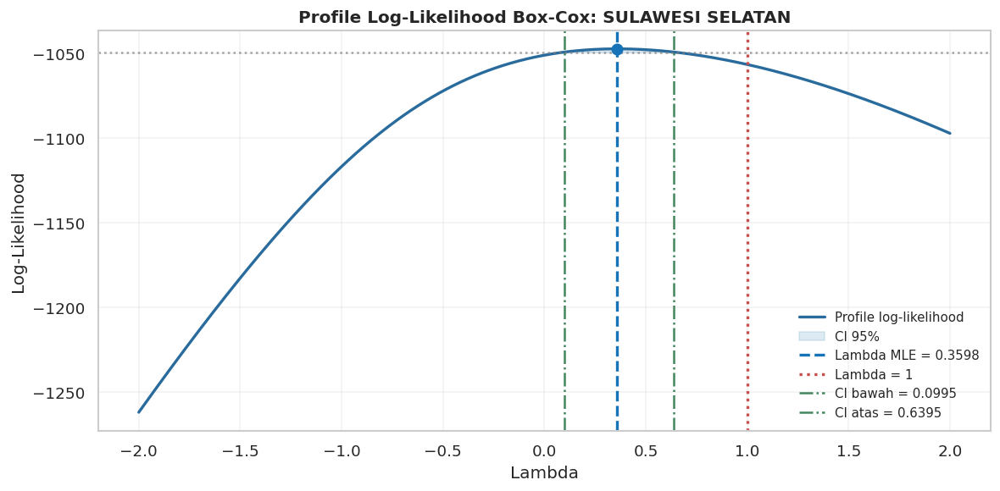

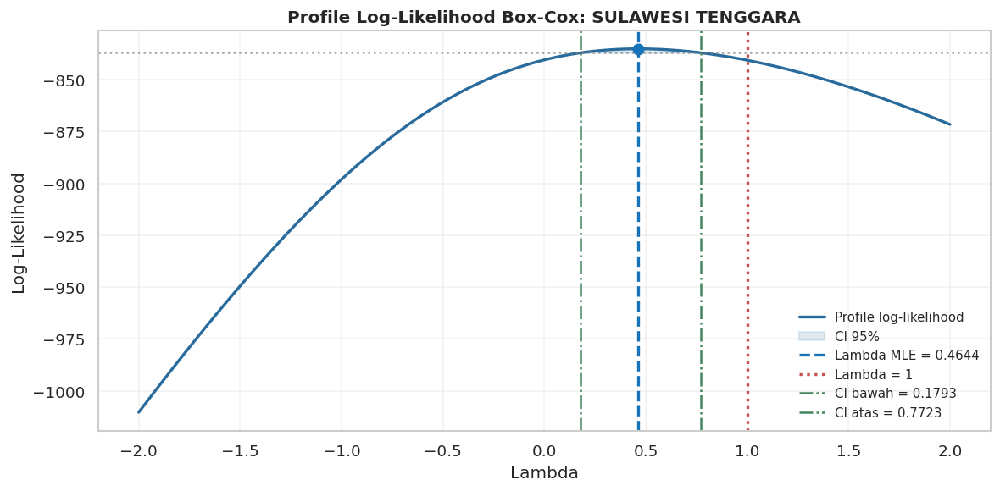


3.2 RINGKASAN PROFILE LOG-LIKELIHOOD


,Provinsi,Lambda MLE,CI Bawah 95%,CI Atas 95%,Lambda = 1 dalam CI,Lambda Digunakan,Transformasi Diterapkan
0,SULAWESI UTARA,-0.02354,-0.69726,0.64558,Tidak,-0.02354,Ya
1,GORONTALO,0.38256,0.11366,0.66053,Tidak,0.38256,Ya
2,SULAWESI TENGAH,0.49350,0.06664,0.93902,Tidak,0.49350,Ya
3,SULAWESI BARAT,0.23421,-0.04286,0.51278,Tidak,0.23421,Ya
4,SULAWESI SELATAN,0.35978,0.09950,0.63950,Tidak,0.35978,Ya
5,SULAWESI TENGGARA,0.46437,0.17927,0.77226,Tidak,0.46437,Ya



3.4 RINGKASAN LAMBDA YANG DIGUNAKAN


,Provinsi,Lambda MLE,Lambda Digunakan,CI Bawah,CI Atas,Shift,Transformasi
0,SULAWESI UTARA,-0.02354,-0.02354,-0.69726,0.64558,0.0,Box-Cox
1,GORONTALO,0.38256,0.38256,0.11366,0.66053,0.0,Box-Cox
2,SULAWESI TENGAH,0.49350,0.49350,0.06664,0.93902,0.0,Box-Cox
3,SULAWESI BARAT,0.23421,0.23421,-0.04286,0.51278,0.0,Box-Cox
4,SULAWESI SELATAN,0.35978,0.35978,0.09950,0.63950,0.0,Box-Cox
5,SULAWESI TENGGARA,0.46437,0.46437,0.17927,0.77226,0.0,Box-Cox



DATA SEBELUM DAN SESUDAH TRANSFORMASI


,Provinsi,Tanggal,Y Sebelum,Y Setelah Shift,Y Setelah Box-Cox
0,SULAWESI UTARA,2018-01-01,26677.21,26677.21,9.06121
1,SULAWESI UTARA,2018-02-01,14652.50,14652.50,8.58648
2,SULAWESI UTARA,2018-03-01,41605.09,41605.09,9.40900
3,SULAWESI UTARA,2018-04-01,29068.24,29068.24,9.12867
4,SULAWESI UTARA,2018-05-01,33347.36,33347.36,9.23631
5,SULAWESI UTARA,2018-06-01,25906.20,25906.20,9.03813
6,SULAWESI UTARA,2018-07-01,30869.56,30869.56,9.17584
7,SULAWESI UTARA,2018-08-01,32351.24,32351.24,9.21257
8,SULAWESI UTARA,2018-09-01,25036.49,25036.49,9.01123
9,SULAWESI UTARA,2018-10-01,21229.69,21229.69,8.88104


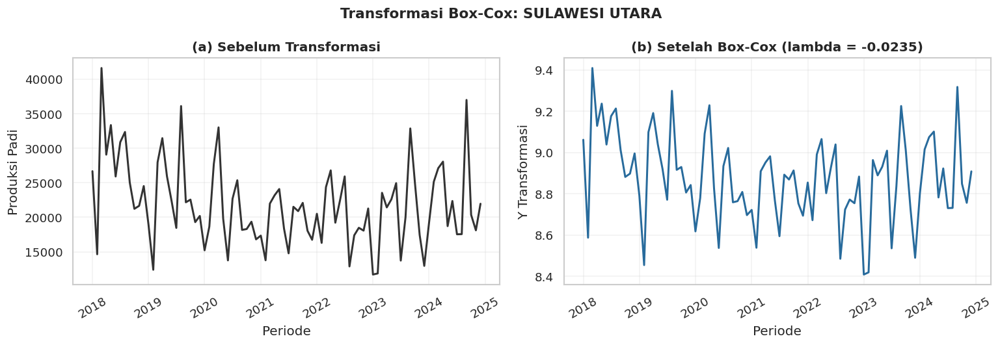

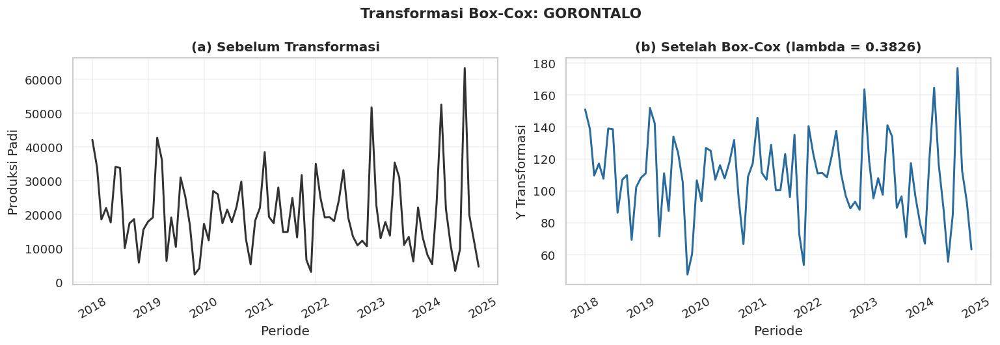

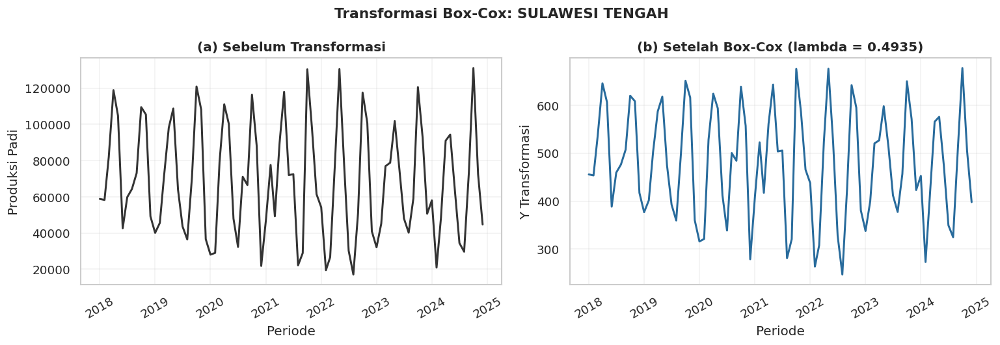

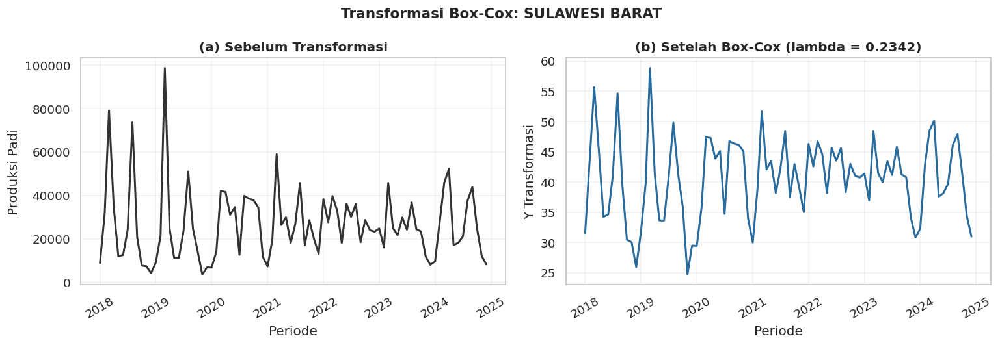

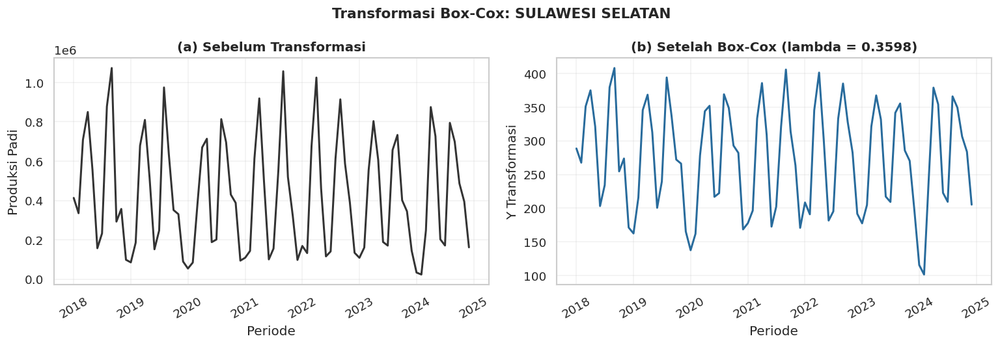

...

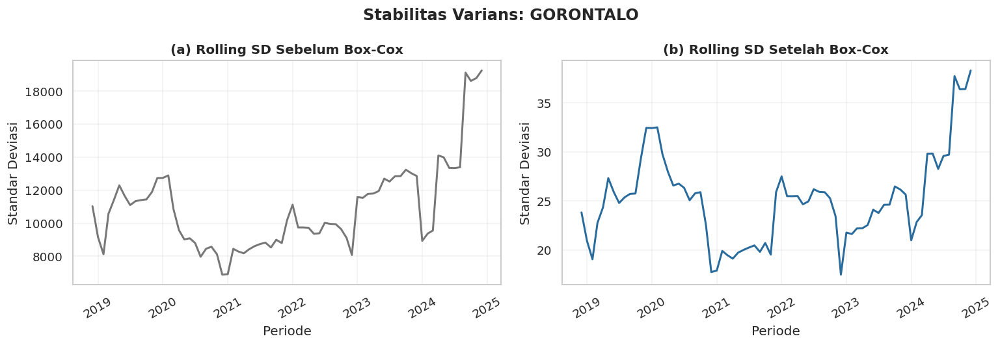

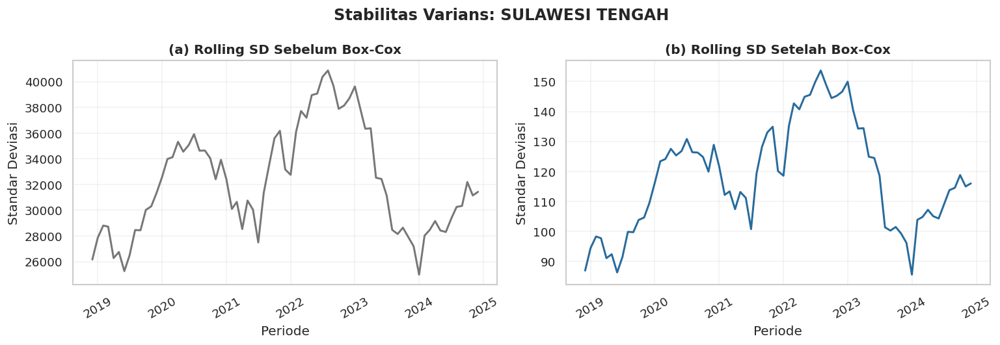

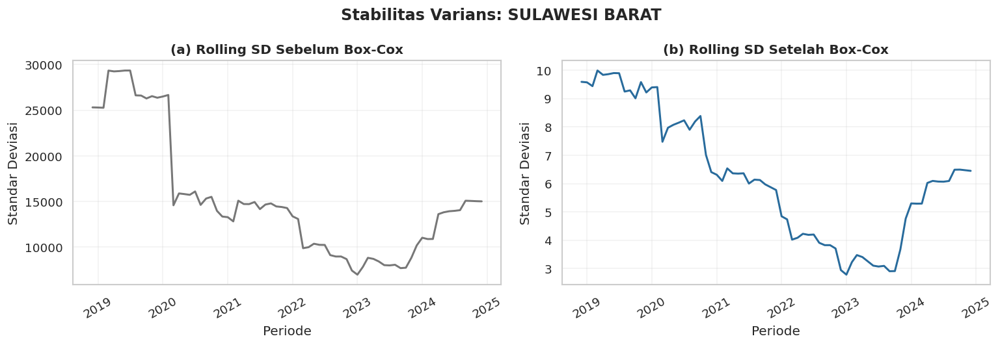

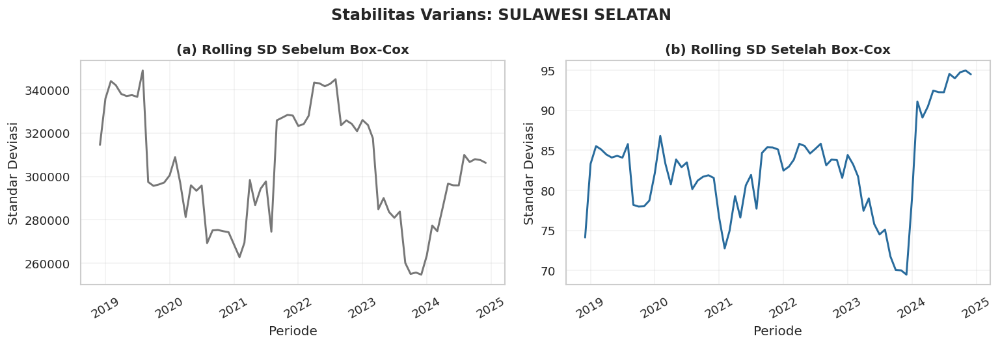

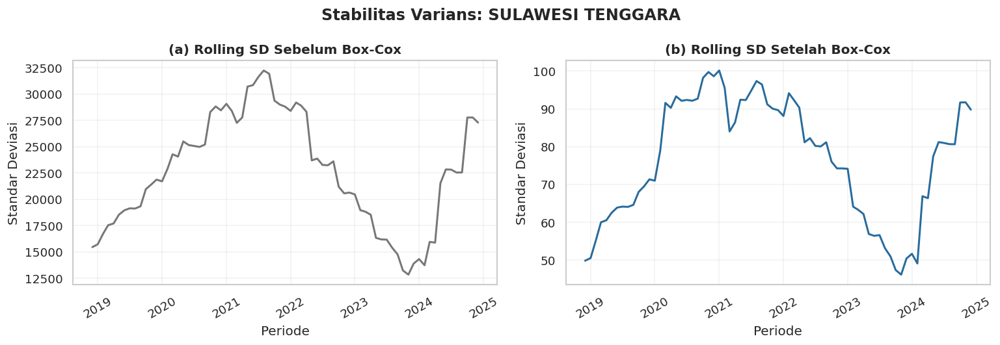


RINGKASAN AKHIR TRANSFORMASI BOX-COX
Jumlah provinsi: 6
Provinsi yang ditransformasi: 6

Variabel hasil:
- boxcox_info
- y_train_trans
- boxcox_visual
- tabel_boxcox
- boxcox_profile_rows
- tabel_boxcox_profile
- tabel_lambda_transformasi
- tabel_data_boxcox
- transform_y()
- inverse_y()

Folder grafik Box-Cox:
/content/Hasil_Analisis_Padi_Sulawesi/Grafik_Jurnal/BoxCox


In [ ]:

# ============================================================
# 3. TRANSFORMASI BOX-COX PER PROVINSI
# ============================================================
# Menggunakan data TRAINING saja untuk estimasi lambda.
#
# Variabel yang harus tersedia:
# PROVINSI_SULAWESI, train_test, ALPHA
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from scipy import stats
from scipy.stats import chi2
from scipy.special import inv_boxcox
from IPython.display import display

sns.set_theme(style="whitegrid")

ALPHA = 0.05

# Folder output lokal Colab
FOLDER_UTAMA = "/content/Hasil_Analisis_Padi_Sulawesi"
FOLDER_GRAFIK = os.path.join(
    FOLDER_UTAMA,
    "Grafik_Jurnal"
)
FOLDER_BOXCOX = os.path.join(
    FOLDER_GRAFIK,
    "BoxCox"
)

os.makedirs(FOLDER_BOXCOX, exist_ok=True)


def simpan_boxcox(fig, nama):
    """Simpan grafik Box-Cox dalam PNG dan PDF."""
    nama = str(nama).replace(" ", "_").replace("/", "-")

    fig.savefig(
        os.path.join(FOLDER_BOXCOX, nama + ".png"),
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        os.path.join(FOLDER_BOXCOX, nama + ".pdf"),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


def format_tanggal_boxcox(ax):
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )
    ax.tick_params(axis="x", rotation=30)


# ============================================================
# 3.1 ESTIMASI LAMBDA DAN TRANSFORMASI BOX-COX
# ============================================================

boxcox_info = {}
y_train_trans = {}
boxcox_visual = {}
boxcox_rows = []

for prov in PROVINSI_SULAWESI:

    y_asli = (
        train_test[prov]["train"]["Y"]
        .astype(float)
        .dropna()
        .sort_index()
    )

    # Box-Cox mensyaratkan nilai positif
    shift = max(
        0.0,
        1.0 - float(y_asli.min())
    )

    y_positif = y_asli + shift

    if len(y_positif) < 3 or y_positif.nunique() < 3:
        raise ValueError(
            f"Data {prov} tidak cukup untuk estimasi Box-Cox."
        )

    # Estimasi lambda optimal dan CI 95%
    y_bc, lambda_hat, ci = stats.boxcox(
        y_positif.to_numpy(),
        alpha=ALPHA
    )

    ci_lower = float(ci[0])
    ci_upper = float(ci[1])

    # Keputusan berdasarkan apakah lambda=1
    # termasuk dalam interval kepercayaan
    gunakan_bc = not (
        ci_lower <= 1.0 <= ci_upper
    )

    lambda_used = (
        float(lambda_hat)
        if gunakan_bc
        else 1.0
    )

    if gunakan_bc:
        y_transformasi = pd.Series(
            y_bc,
            index=y_asli.index,
            name="Y_BoxCox"
        )
    else:
        y_transformasi = y_asli.copy()
        y_transformasi.name = "Y_BoxCox"

    boxcox_info[prov] = {
        "shift": float(shift),
        "lambda_hat": float(lambda_hat),
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "use_boxcox": bool(gunakan_bc),
        "lambda_used": float(lambda_used)
    }

    y_train_trans[prov] = y_transformasi

    boxcox_visual[prov] = pd.DataFrame({
        "Y_Asli": y_asli,
        "Y_Positif": y_positif,
        "Y_BoxCox": y_transformasi
    })

    boxcox_rows.append({
        "Provinsi": prov,
        "Lambda MLE": float(lambda_hat),
        "CI Bawah 95%": ci_lower,
        "CI Atas 95%": ci_upper,
        "Lambda = 1 dalam CI": (
            "Ya" if not gunakan_bc else "Tidak"
        ),
        "Lambda Digunakan": lambda_used,
        "Shift": shift,
        "Transformasi Diterapkan": (
            "Ya" if gunakan_bc else "Tidak"
        )
    })


tabel_boxcox = pd.DataFrame(boxcox_rows)

print("=" * 70)
print("3.1 HASIL ESTIMASI DAN TRANSFORMASI BOX-COX")
print("=" * 70)

display(tabel_boxcox.round(5))


# ============================================================
# 3.2 PROFILE LOG-LIKELIHOOD BOX-COX
# ============================================================

boxcox_profile_rows = []

for prov in PROVINSI_SULAWESI:

    info = boxcox_info[prov]
    visual = boxcox_visual[prov]

    y_positif = visual["Y_Positif"].to_numpy()

    lambda_mle = info["lambda_hat"]
    ci_lower = info["ci_lower"]
    ci_upper = info["ci_upper"]

    lambda_grid = np.linspace(
        min(-2.0, ci_lower - 0.5),
        max(2.0, ci_upper + 0.5),
        801
    )

    loglik_values = np.array([
        stats.boxcox_llf(lam, y_positif)
        for lam in lambda_grid
    ])

    max_loglik = stats.boxcox_llf(
        lambda_mle,
        y_positif
    )

    cutoff = (
        max_loglik
        - 0.5 * chi2.ppf(1 - ALPHA, df=1)
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        lambda_grid,
        loglik_values,
        color="#286B9C",
        linewidth=2,
        label="Profile log-likelihood"
    )

    mask_ci = (
        (lambda_grid >= ci_lower)
        & (lambda_grid <= ci_upper)
    )

    ax.fill_between(
        lambda_grid,
        loglik_values,
        cutoff,
        where=mask_ci,
        color="#8FBAD6",
        alpha=0.3,
        label="CI 95%"
    )

    ax.axvline(
        lambda_mle,
        color="#1673B8",
        linestyle="--",
        linewidth=2,
        label=f"Lambda MLE = {lambda_mle:.4f}"
    )

    ax.axvline(
        1.0,
        color="#C94F4F",
        linestyle=":",
        linewidth=2,
        label="Lambda = 1"
    )

    ax.axvline(
        ci_lower,
        color="#43865D",
        linestyle="-.",
        label=f"CI bawah = {ci_lower:.4f}"
    )

    ax.axvline(
        ci_upper,
        color="#43865D",
        linestyle="-.",
        label=f"CI atas = {ci_upper:.4f}"
    )

    ax.axhline(
        cutoff,
        color="gray",
        linestyle=":",
        alpha=0.7
    )

    ax.scatter(
        [lambda_mle],
        [max_loglik],
        color="#1673B8",
        s=55,
        zorder=5
    )

    ax.set_title(
        f"Profile Log-Likelihood Box-Cox: {prov}",
        fontweight="bold"
    )
    ax.set_xlabel("Lambda")
    ax.set_ylabel("Log-Likelihood")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.25)

    fig.tight_layout()

    simpan_boxcox(
        fig,
        f"Profile_LogLikelihood_{prov}"
    )

    boxcox_profile_rows.append({
        "Provinsi": prov,
        "Lambda MLE": lambda_mle,
        "CI Bawah 95%": ci_lower,
        "CI Atas 95%": ci_upper,
        "Lambda = 1 dalam CI": (
            "Ya" if ci_lower <= 1 <= ci_upper
            else "Tidak"
        ),
        "Lambda Digunakan": info["lambda_used"],
        "Transformasi Diterapkan": (
            "Ya" if info["use_boxcox"] else "Tidak"
        )
    })


tabel_boxcox_profile = pd.DataFrame(
    boxcox_profile_rows
)

print("\n3.2 RINGKASAN PROFILE LOG-LIKELIHOOD")
display(tabel_boxcox_profile.round(5))


# ============================================================
# 3.3 FUNGSI TRANSFORMASI DAN INVERS BOX-COX
# ============================================================

def transform_y(series, prov):
    """
    Transformasi Y menggunakan parameter Box-Cox
    yang dihitung dari data training.
    """

    info = boxcox_info[prov]

    vals = np.asarray(series, dtype=float)

    if info["use_boxcox"]:

        nilai_positif = vals + info["shift"]

        if np.any(nilai_positif <= 0):
            raise ValueError(
                f"Data {prov} tidak positif setelah shift."
            )

        hasil = stats.boxcox(
            nilai_positif,
            lmbda=info["lambda_used"]
        )

    else:
        hasil = vals

    return pd.Series(
        hasil,
        index=series.index,
        name="Y_Transformasi"
    )


def inverse_y(values, prov):
    """
    Mengembalikan nilai transformasi
    ke skala produksi padi asli.
    """

    info = boxcox_info[prov]

    vals = np.asarray(values, dtype=float)

    if info["use_boxcox"]:

        hasil = (
            inv_boxcox(
                vals,
                info["lambda_used"]
            )
            - info["shift"]
        )

    else:
        hasil = vals

    return hasil


# ============================================================
# 3.4 DATA SEBELUM DAN SESUDAH TRANSFORMASI
# ============================================================

hasil_data_boxcox = []
ringkasan_lambda = []

for prov in PROVINSI_SULAWESI:

    info = boxcox_info[prov]
    visual = boxcox_visual[prov]

    df = visual.reset_index().copy()

    df = df.rename(columns={
        df.columns[0]: "Tanggal",
        "Y_Asli": "Y Sebelum",
        "Y_Positif": "Y Setelah Shift",
        "Y_BoxCox": "Y Setelah Box-Cox"
    })

    df.insert(0, "Provinsi", prov)

    hasil_data_boxcox.append(df)

    ringkasan_lambda.append({
        "Provinsi": prov,
        "Lambda MLE": info["lambda_hat"],
        "Lambda Digunakan": info["lambda_used"],
        "CI Bawah": info["ci_lower"],
        "CI Atas": info["ci_upper"],
        "Shift": info["shift"],
        "Transformasi": (
            "Box-Cox"
            if info["use_boxcox"]
            else "Skala asli"
        )
    })

tabel_data_boxcox = pd.concat(
    hasil_data_boxcox,
    ignore_index=True
)

tabel_lambda_transformasi = pd.DataFrame(
    ringkasan_lambda
)

print("\n3.4 RINGKASAN LAMBDA YANG DIGUNAKAN")
display(tabel_lambda_transformasi.round(5))

print("\nDATA SEBELUM DAN SESUDAH TRANSFORMASI")
display(tabel_data_boxcox.head(20).round(5))


# ============================================================
# 3.5 GRAFIK DERET WAKTU SEBELUM DAN SESUDAH BOX-COX
# ============================================================

for prov in PROVINSI_SULAWESI:

    visual = boxcox_visual[prov]
    info = boxcox_info[prov]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4.5)
    )

    axes[0].plot(
        visual.index,
        visual["Y_Asli"],
        color="#333333",
        linewidth=1.8
    )

    axes[0].set_title(
        "(a) Sebelum Transformasi",
        fontweight="bold"
    )
    axes[0].set_ylabel("Produksi Padi")
    axes[0].set_xlabel("Periode")

    axes[1].plot(
        visual.index,
        visual["Y_BoxCox"],
        color="#286B9C",
        linewidth=1.8
    )

    axes[1].set_title(
        f"(b) Setelah Box-Cox "
        f"(lambda = {info['lambda_used']:.4f})",
        fontweight="bold"
    )
    axes[1].set_ylabel("Y Transformasi")
    axes[1].set_xlabel("Periode")

    for ax in axes:
        format_tanggal_boxcox(ax)
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"Transformasi Box-Cox: {prov}",
        fontweight="bold",
        fontsize=13
    )

    fig.tight_layout()

    simpan_boxcox(
        fig,
        f"Sebelum_Sesudah_BoxCox_{prov}"
    )


# ============================================================
# 3.6 HISTOGRAM SEBELUM DAN SESUDAH BOX-COX
# ============================================================

for prov in PROVINSI_SULAWESI:

    visual = boxcox_visual[prov]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4.5)
    )

    sns.histplot(
        visual["Y_Asli"],
        kde=True,
        color="#777777",
        ax=axes[0]
    )

    axes[0].set_title(
        "Distribusi Sebelum Box-Cox",
        fontweight="bold"
    )
    axes[0].set_xlabel("Produksi Padi")
    axes[0].set_ylabel("Frekuensi")

    sns.histplot(
        visual["Y_BoxCox"],
        kde=True,
        color="#286B9C",
        ax=axes[1]
    )

    axes[1].set_title(
        "Distribusi Setelah Box-Cox",
        fontweight="bold"
    )
    axes[1].set_xlabel("Y Transformasi")
    axes[1].set_ylabel("Frekuensi")

    fig.suptitle(
        f"Distribusi Produksi Padi: {prov}",
        fontweight="bold"
    )

    fig.tight_layout()

    simpan_boxcox(
        fig,
        f"Histogram_BoxCox_{prov}"
    )


# ============================================================
# 3.7 ROLLING STANDARD DEVIATION
# PEMERIKSAAN STABILITAS VARIANS
# ============================================================

WINDOW = 12

for prov in PROVINSI_SULAWESI:

    visual = boxcox_visual[prov]

    std_asli = (
        visual["Y_Asli"]
        .rolling(WINDOW, min_periods=WINDOW)
        .std()
    )

    std_boxcox = (
        visual["Y_BoxCox"]
        .rolling(WINDOW, min_periods=WINDOW)
        .std()
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 4.5)
    )

    axes[0].plot(
        std_asli.index,
        std_asli,
        color="#777777",
        linewidth=1.8
    )

    axes[0].set_title(
        "(a) Rolling SD Sebelum Box-Cox",
        fontweight="bold"
    )
    axes[0].set_ylabel("Standar Deviasi")

    axes[1].plot(
        std_boxcox.index,
        std_boxcox,
        color="#286B9C",
        linewidth=1.8
    )

    axes[1].set_title(
        "(b) Rolling SD Setelah Box-Cox",
        fontweight="bold"
    )
    axes[1].set_ylabel("Standar Deviasi")

    for ax in axes:
        ax.set_xlabel("Periode")
        format_tanggal_boxcox(ax)
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"Stabilitas Varians: {prov}",
        fontweight="bold"
    )

    fig.tight_layout()

    simpan_boxcox(
        fig,
        f"Rolling_SD_BoxCox_{prov}"
    )


# ============================================================
# 3.8 RINGKASAN HASIL BOX-COX
# ============================================================

print("\n" + "=" * 70)
print("RINGKASAN AKHIR TRANSFORMASI BOX-COX")
print("=" * 70)

print("Jumlah provinsi:", len(PROVINSI_SULAWESI))

print(
    "Provinsi yang ditransformasi:",
    sum(
        info["use_boxcox"]
        for info in boxcox_info.values()
    )
)

print("\nVariabel hasil:")
print("- boxcox_info")
print("- y_train_trans")
print("- boxcox_visual")
print("- tabel_boxcox")
print("- boxcox_profile_rows")
print("- tabel_boxcox_profile")
print("- tabel_lambda_transformasi")
print("- tabel_data_boxcox")
print("- transform_y()")
print("- inverse_y()")

print("\nFolder grafik Box-Cox:")
print(FOLDER_BOXCOX)


# 4. Penanganan Stasioneritas: Differencing dan ACF/PACF Sesudahnya

Jika ADF menunjukkan data belum stasioner, periksa kombinasi differencing biasa (`d`) dan musiman (`D`, periode 12). Pemilihan otomatis di bawah memilih kombinasi dengan differencing paling ringan yang memenuhi ADF (p-value < 0,05). Hasil tetap perlu dikonfirmasi dengan grafik dan diagnostik model. ADF standar tidak secara khusus menguji akar unit musiman.

,Provinsi,d,D,ADF Statistic,ADF p-value,N
0,SULAWESI UTARA,0,0,-2.396499,1.427271e-01,84
1,SULAWESI UTARA,0,1,-3.014317,3.357879e-02,72
2,SULAWESI UTARA,1,0,-5.941525,2.255018e-07,83
3,SULAWESI UTARA,1,1,-3.166412,2.201306e-02,71
4,GORONTALO,0,0,-4.903800,3.428517e-05,84
5,GORONTALO,0,1,-3.106114,2.610402e-02,72
6,GORONTALO,1,0,-6.324100,3.015946e-08,83
7,GORONTALO,1,1,-5.293480,5.648527e-06,71
8,SULAWESI TENGAH,0,0,-5.215970,8.155479e-06,84
9,SULAWESI TENGAH,0,1,-3.441885,9.611223e-03,72


,Provinsi,d,D
0,SULAWESI UTARA,1,0
1,GORONTALO,0,0
2,SULAWESI TENGAH,0,0
3,SULAWESI BARAT,1,0
4,SULAWESI SELATAN,1,0
5,SULAWESI TENGGARA,0,0


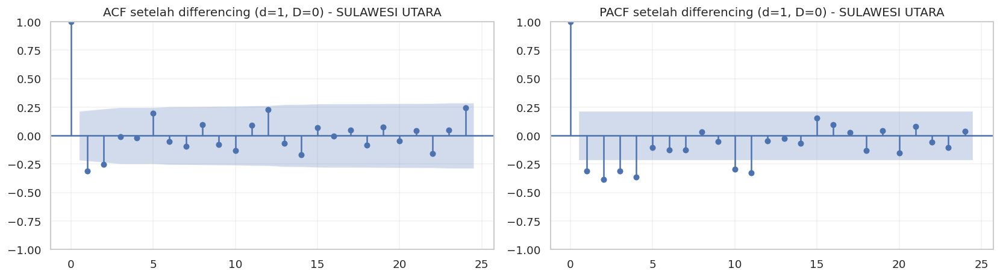

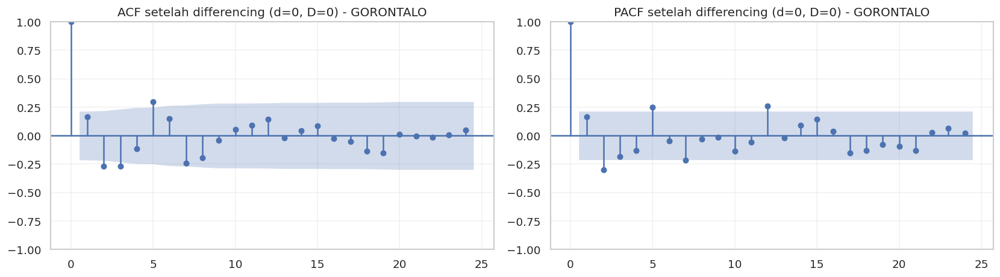

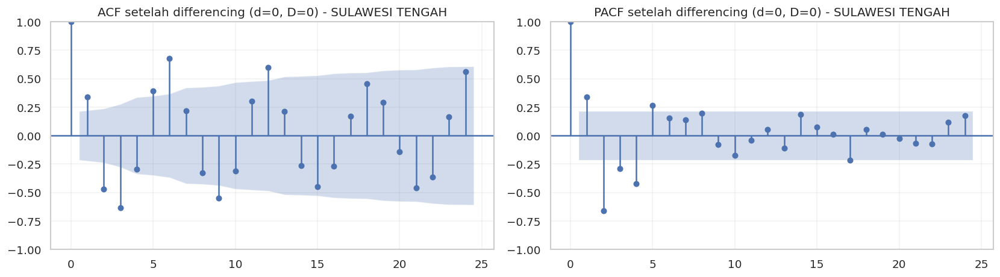

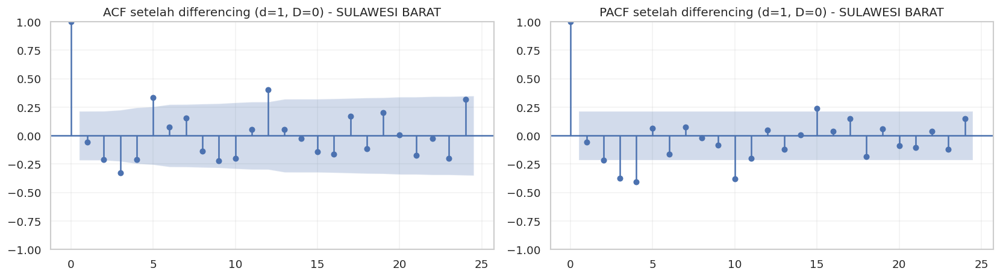

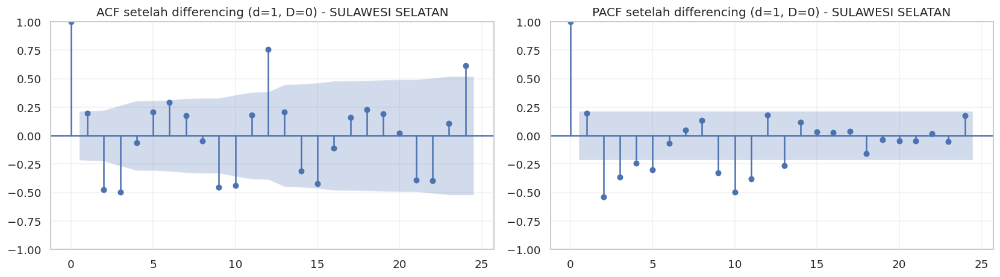

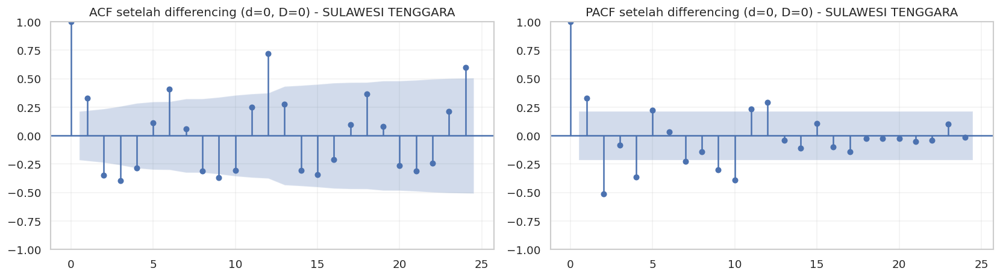

,Provinsi,d,D,ADF Statistic setelah,ADF p-value setelah,Kesimpulan
0,SULAWESI UTARA,1,0,-5.941525,2.255018e-07,Stasioner menurut ADF
1,GORONTALO,0,0,-4.903800,3.428517e-05,Stasioner menurut ADF
2,SULAWESI TENGAH,0,0,-5.215970,8.155479e-06,Stasioner menurut ADF
3,SULAWESI BARAT,1,0,-7.252453,1.765566e-10,Stasioner menurut ADF
4,SULAWESI SELATAN,1,0,-5.321087,4.950974e-06,Stasioner menurut ADF
5,SULAWESI TENGGARA,0,0,-2.997801,3.510024e-02,Stasioner menurut ADF


In [ ]:
def apply_diff(series, d, D, seasonal_period=12):
    z = series.copy()
    if D == 1:
        z = z.diff(seasonal_period)
    if d == 1:
        z = z.diff()
    return z.dropna()

kombinasi_diff = [(0,0), (0,1), (1,0), (1,1)]
orde_diff = {}
hasil_adf_diff = []

for prov in PROVINSI_SULAWESI:
    y = y_train_trans[prov]
    kandidat = []

    for d, D in kombinasi_diff:
        z = apply_diff(y, d, D, S)
        stat, pval, *_ = adfuller(z.dropna(), autolag="AIC")
        hasil_adf_diff.append({
            "Provinsi": prov, "d": d, "D": D,
            "ADF Statistic": stat, "ADF p-value": pval,
            "N": len(z)
        })
        if pval < ALPHA:
            kandidat.append((d, D))

    # Prioritas differencing paling sedikit; bila sama, nonmusiman lebih dulu
    if kandidat:
        kandidat.sort(key=lambda x: (x[0] + x[1], x[1], x[0]))
        orde_diff[prov] = kandidat[0]
    else:
        # Jika belum lolos ADF pada kombinasi sederhana, gunakan (1,1)
        # dan evaluasi ulang; jangan menganggap otomatis stasioner.
        orde_diff[prov] = (1, 1)

tabel_adf_diff = pd.DataFrame(hasil_adf_diff)
display(tabel_adf_diff)
display(pd.DataFrame([
    {"Provinsi": p, "d": orde_diff[p][0], "D": orde_diff[p][1]}
    for p in PROVINSI_SULAWESI
]))

# 4.1 ADF, ACF, PACF setelah differencing terpilih
data_stasioner = {}
adf_setelah = []

for prov in PROVINSI_SULAWESI:
    d, D = orde_diff[prov]
    z = apply_diff(y_train_trans[prov], d, D, S)
    data_stasioner[prov] = z

    stat, pval, *_ = adfuller(z, autolag="AIC")
    adf_setelah.append({
        "Provinsi": prov, "d": d, "D": D,
        "ADF Statistic setelah": stat,
        "ADF p-value setelah": pval,
        "Kesimpulan": "Stasioner menurut ADF" if pval < ALPHA else "Belum stasioner menurut ADF"
    })

    max_lag = min(24, max(1, len(z)//2 - 1))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(z, lags=max_lag, ax=axes[0])
    plot_pacf(z, lags=max_lag, ax=axes[1], method="ywm")
    axes[0].set_title(f"ACF setelah differencing (d={d}, D={D}) - {prov}")
    axes[1].set_title(f"PACF setelah differencing (d={d}, D={D}) - {prov}")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(adf_setelah))

# 5. Identifikasi Model SARIMA dan SARIMAX

ACF/PACF menjadi panduan untuk menentukan kandidat `p`, `q`, `P`, dan `Q`. Notebook melakukan pencarian grid terbatas sebagai bantuan komputasi. Orde `d` dan `D` mengikuti tahap 4, sedangkan periode musiman `s=12`.

- SARIMA: hanya menggunakan Y.
- SARIMAX: menggunakan Y dengan variabel eksogen X1 dan X2.

Variabel eksogen distandardisasi menggunakan rerata dan simpangan baku data training. Nilai standar yang sama diterapkan ke data testing.

In [ ]:
# Siapkan X1 dan X2 dengan standardisasi berdasarkan training
exog_info = {}
exog_train = {}
exog_test = {}

for prov in PROVINSI_SULAWESI:
    tr = train_test[prov]["train"]
    te = train_test[prov]["test"]

    mean_x = tr[EXOG].mean()
    std_x = tr[EXOG].std().replace(0, 1)

    exog_info[prov] = {"mean": mean_x, "std": std_x}
    exog_train[prov] = (tr[EXOG] - mean_x) / std_x
    exog_test[prov] = (te[EXOG] - mean_x) / std_x

# SARIMAX model menerima data Y pada skala hasil keputusan Box-Cox
def fit_sarimax(y, exog, order, seasonal_order):
    model = SARIMAX(
        y,
        exog=exog,
        order=order,
        seasonal_order=seasonal_order,
        trend="n" if (order[1] > 0 or seasonal_order[1] > 0) else "c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    return model.fit(disp=False, maxiter=300)

def grid_search_model(y, exog, d, D):
    rows = []
    best_result = None
    best_aic = np.inf

    for p, q, P, Q in itertools.product(
        P_VALUES, Q_VALUES, SP_VALUES, SQ_VALUES
    ):
        order = (p, d, q)
        seasonal_order = (P, D, Q, S)

        try:
            result = fit_sarimax(y, exog, order, seasonal_order)
            converged = result.mle_retvals.get("converged", False)
            rows.append({
                "order": order,
                "seasonal_order": seasonal_order,
                "AIC": result.aic,
                "BIC": result.bic,
                "converged": converged
            })
            if np.isfinite(result.aic) and result.aic < best_aic:
                best_aic = result.aic
                best_result = result
        except Exception:
            continue

    tabel = pd.DataFrame(rows).sort_values("AIC") if rows else pd.DataFrame()
    return best_result, tabel

kandidat_model = {}
model_terestimasi = {}
rows_kandidat = []

for prov in PROVINSI_SULAWESI:
    y = y_train_trans[prov]
    d, D = orde_diff[prov]

    # SARIMA tanpa eksogen
    for jenis, ex in [
        ("SARIMA", None),
        ("SARIMAX", exog_train[prov])
    ]:
        result, tabel = grid_search_model(y, ex, d, D)
        if result is None:
            raise RuntimeError(f"Tidak ada kandidat berhasil untuk {prov} - {jenis}")

        model_terestimasi[(prov, jenis)] = result
        kandidat_model[(prov, jenis)] = tabel

        for _, row in tabel.iterrows():
            rows_kandidat.append({
                "Provinsi": prov,
                "Model": jenis,
                **row.to_dict()
            })

        print(
            f"{prov} | {jenis} | order={result.model.order} | "
            f"seasonal={result.model.seasonal_order} | AIC={result.aic:.3f}"
        )

tabel_kandidat = pd.DataFrame(rows_kandidat)
display(tabel_kandidat.sort_values(["Provinsi", "Model", "AIC"]).groupby(
    ["Provinsi", "Model"]
).head(5))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SULAWESI UTARA | SARIMA | order=(2, 1, 1) | seasonal=(1, 0, 1, 12) | AIC=-32.835


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SULAWESI UTARA | SARIMAX | order=(1, 1, 2) | seasonal=(0, 0, 0, 12) | AIC=-235.041


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


GORONTALO | SARIMA | order=(2, 0, 2) | seasonal=(1, 0, 1, 12) | AIC=629.545
GORONTALO | SARIMAX | order=(2, 0, 2) | seasonal=(0, 0, 1, 12) | AIC=470.572
SULAWESI TENGAH | SARIMA | order=(0, 0, 2) | seasonal=(1, 0, 1, 12) | AIC=775.604
SULAWESI TENGAH | SARIMAX | order=(0, 0, 2) | seasonal=(0, 0, 1, 12) | AIC=621.374
SULAWESI BARAT | SARIMA | order=(2, 1, 2) | seasonal=(1, 0, 1, 12) | AIC=401.075
SULAWESI BARAT | SARIMAX | order=(1, 1, 2) | seasonal=(1, 0, 1, 12) | AIC=253.470
SULAWESI SELATAN | SARIMA | order=(0, 1, 2) | seasonal=(1, 0, 1, 12) | AIC=661.006
SULAWESI SELATAN | SARIMAX | order=(0, 1, 2) | seasonal=(1, 0, 1, 12) | AIC=570.251
SULAWESI TENGGARA | SARIMA | order=(1, 0, 2) | seasonal=(1, 0, 1, 12) | AIC=702.295
SULAWESI TENGGARA | SARIMAX | order=(0, 0, 2) | seasonal=(1, 0, 1, 12) | AIC=568.865


,Provinsi,Model,order,seasonal_order,AIC,BIC,converged
72,GORONTALO,SARIMA,"(2, 0, 2)","(1, 0, 1, 12)",629.545149,647.418001,True
73,GORONTALO,SARIMA,"(2, 0, 2)","(0, 0, 1, 12)",636.339687,651.978433,True
74,GORONTALO,SARIMA,"(2, 0, 2)","(1, 0, 0, 12)",641.906587,657.646053,True
75,GORONTALO,SARIMA,"(1, 0, 2)","(1, 0, 1, 12)",643.973894,659.612640,True
76,GORONTALO,SARIMA,"(1, 0, 2)","(0, 0, 1, 12)",645.700188,659.104827,True
108,GORONTALO,SARIMAX,"(2, 0, 2)","(0, 0, 1, 12)",470.571544,490.678502,True
109,GORONTALO,SARIMAX,"(1, 0, 2)","(1, 0, 1, 12)",471.086435,491.193394,True
110,GORONTALO,SARIMAX,"(0, 0, 2)","(1, 0, 1, 12)",471.390712,489.263564,True
111,GORONTALO,SARIMAX,"(0, 0, 2)","(0, 0, 1, 12)",471.672171,487.310916,True
112,GORONTALO,SARIMAX,"(2, 0, 2)","(1, 0, 1, 12)",472.257847,494.598912,True


# 6. Pendugaan Parameter dengan Maximum Likelihood Estimation (MLE)

Parameter SARIMA/SARIMAX diestimasi oleh `statsmodels` melalui MLE pada data training. Tabel berikut merangkum koefisien, standard error, z-statistic, p-value, AIC, dan BIC. Signifikansi parameter ditinjau bersama AIC/BIC dan diagnostik residual, bukan menjadi satu-satunya dasar pemilihan.

In [ ]:
parameter_rows = []
ringkasan_estimasi = []

for prov in PROVINSI_SULAWESI:
    for jenis in ["SARIMA", "SARIMAX"]:
        result = model_terestimasi[(prov, jenis)]
        ringkasan_estimasi.append({
            "Provinsi": prov,
            "Model": jenis,
            "Order": str(result.model.order),
            "Seasonal order": str(result.model.seasonal_order),
            "AIC": result.aic,
            "BIC": result.bic,
            "Log Likelihood": result.llf,
            "Konvergen": result.mle_retvals.get("converged", False)
        })

        for nama, nilai in result.params.items():
            parameter_rows.append({
                "Provinsi": prov,
                "Model": jenis,
                "Parameter": nama,
                "Koefisien": nilai,
                "Std Error": result.bse.get(nama, np.nan),
                "z": result.tvalues.get(nama, np.nan),
                "p-value": result.pvalues.get(nama, np.nan)
            })

tabel_estimasi = pd.DataFrame(ringkasan_estimasi)
tabel_parameter = pd.DataFrame(parameter_rows)

display(tabel_estimasi.round(4))
display(tabel_parameter.round(4))

,Provinsi,Model,Order,Seasonal order,AIC,BIC,Log Likelihood,Konvergen
0,SULAWESI UTARA,SARIMA,"(2, 1, 1)","(1, 0, 1, 12)",-32.8346,-19.4299,22.4173,True
1,SULAWESI UTARA,SARIMAX,"(1, 1, 2)","(0, 0, 0, 12)",-235.0413,-220.7491,123.5206,True
2,GORONTALO,SARIMA,"(2, 0, 2)","(1, 0, 1, 12)",629.5451,647.4180,-306.7726,True
3,GORONTALO,SARIMAX,"(2, 0, 2)","(0, 0, 1, 12)",470.5715,490.6785,-226.2858,True
4,SULAWESI TENGAH,SARIMA,"(0, 0, 2)","(1, 0, 1, 12)",775.6043,789.0090,-381.8022,True
5,SULAWESI TENGAH,SARIMAX,"(0, 0, 2)","(0, 0, 1, 12)",621.3743,637.0130,-303.6871,True
6,SULAWESI BARAT,SARIMA,"(2, 1, 2)","(1, 0, 1, 12)",401.0750,416.6115,-193.5375,True
7,SULAWESI BARAT,SARIMAX,"(1, 1, 2)","(1, 0, 1, 12)",253.4702,271.2263,-118.7351,True
8,SULAWESI SELATAN,SARIMA,"(0, 1, 2)","(1, 0, 1, 12)",661.0056,672.1031,-325.5028,True
9,SULAWESI SELATAN,SARIMAX,"(0, 1, 2)","(1, 0, 1, 12)",570.2512,585.7877,-278.1256,True


,Provinsi,Model,Parameter,Koefisien,Std Error,z,p-value
0,SULAWESI UTARA,SARIMA,ar.L1,0.0367,0.1320,0.2781,0.7810
1,SULAWESI UTARA,SARIMA,ar.L2,-0.3119,0.1274,-2.4480,0.0144
2,SULAWESI UTARA,SARIMA,ma.L1,-0.8982,0.0750,-11.9759,0.0000
3,SULAWESI UTARA,SARIMA,ar.S.L12,0.5894,0.1300,4.5334,0.0000
4,SULAWESI UTARA,SARIMA,ma.S.L12,-0.4429,0.1829,-2.4219,0.0154
...,...,...,...,...,...,...,...
79,SULAWESI TENGGARA,SARIMAX,ma.L1,0.1185,0.1365,0.8681,0.3854
80,SULAWESI TENGGARA,SARIMAX,ma.L2,-0.1330,0.1780,-0.7474,0.4548
81,SULAWESI TENGGARA,SARIMAX,ar.S.L12,0.8631,0.0767,11.2590,0.0000
82,SULAWESI TENGGARA,SARIMAX,ma.S.L12,-1.0003,321.3101,-0.0031,0.9975


# 7. Uji Diagnostik Residual dan Penanganannya

Diagnostik dilakukan terhadap residual model training:

1. **Ljung-Box**: H0 residual tidak memiliki autokorelasi.
2. **Jarque-Bera**: H0 residual berdistribusi normal.
3. **ARCH-LM**: H0 tidak terdapat efek ARCH/heteroskedastisitas bersyarat.

p-value > 0,05 berarti gagal menolak H0. Jika ada pelanggaran, evaluasi ulang orde model, transformasi, pencilan/intervensi, atau pertimbangkan model volatilitas tambahan. Penanganan harus diikuti estimasi ulang dan diagnostik ulang; notebook tidak mengubah model secara otomatis hanya untuk memaksa seluruh uji lolos.

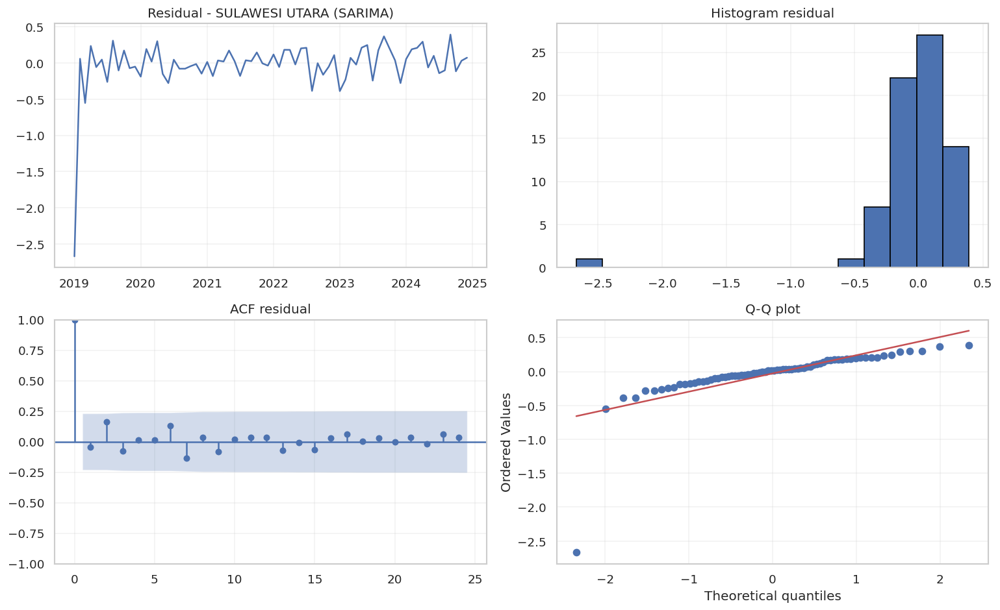

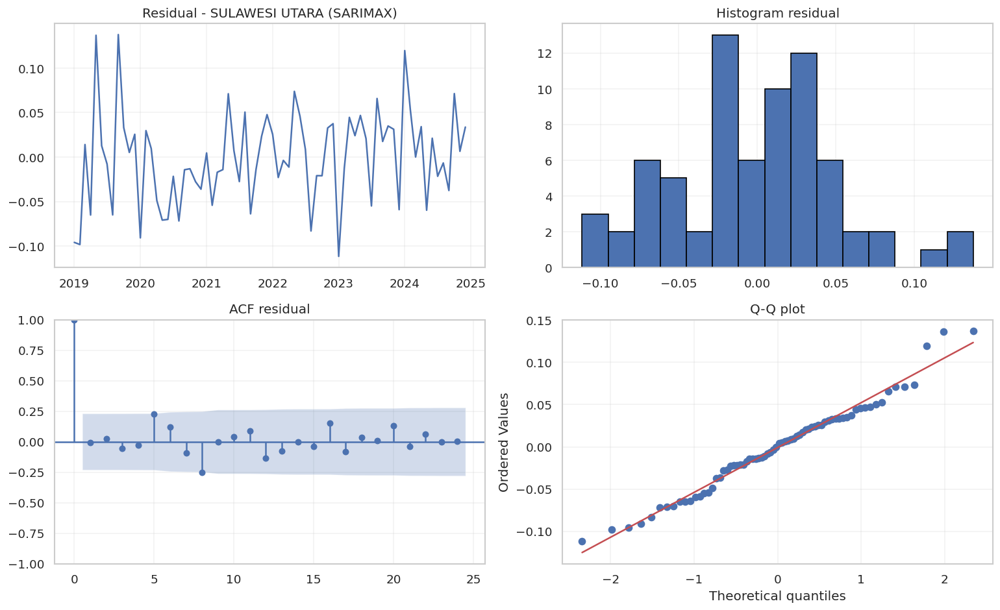

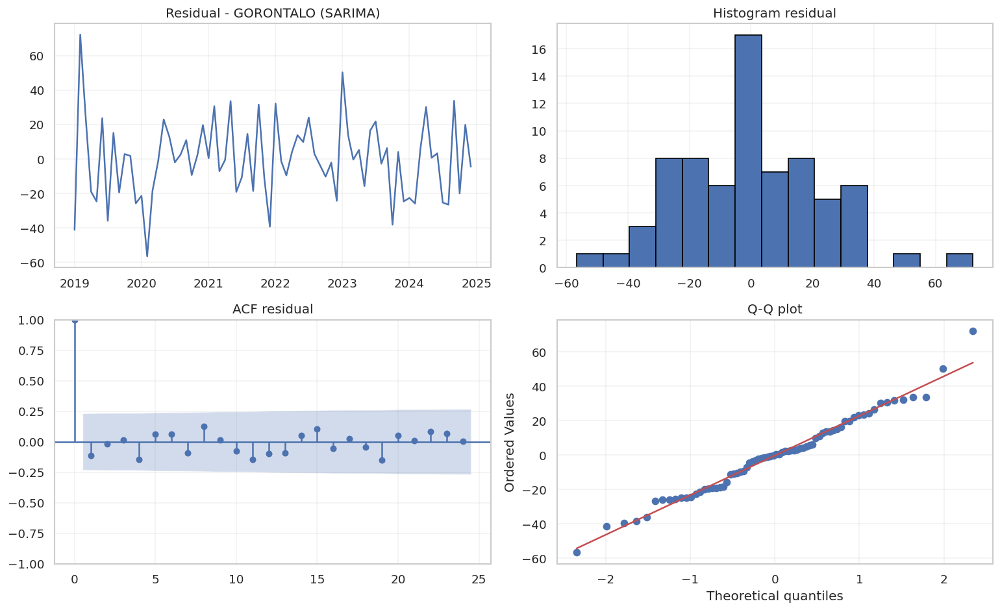

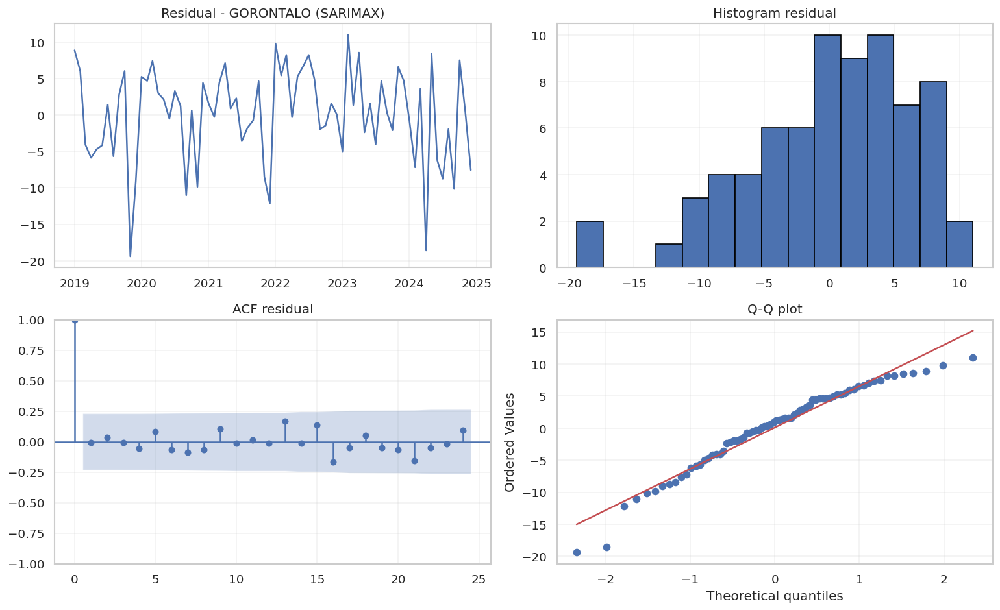

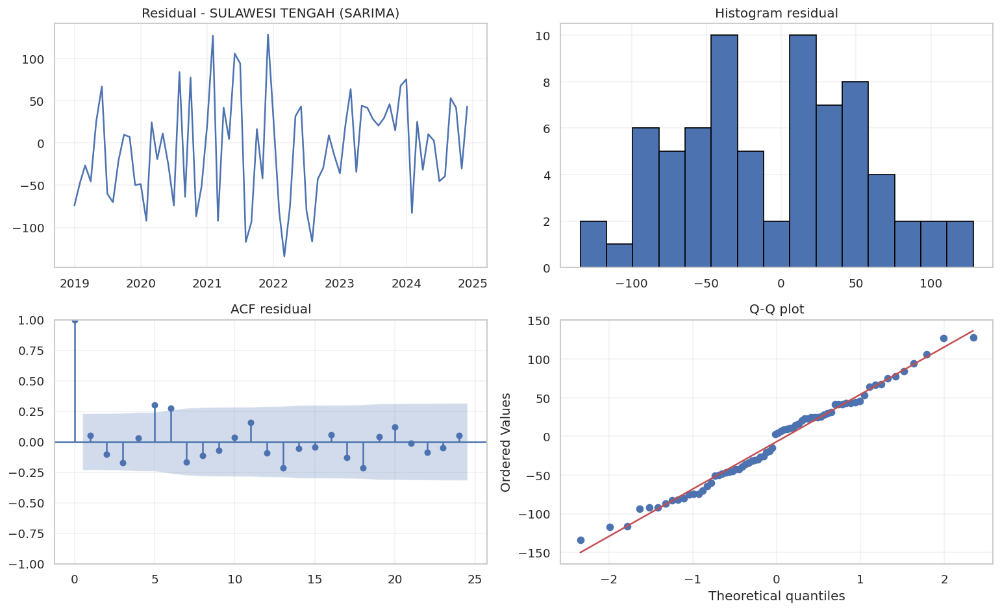

...

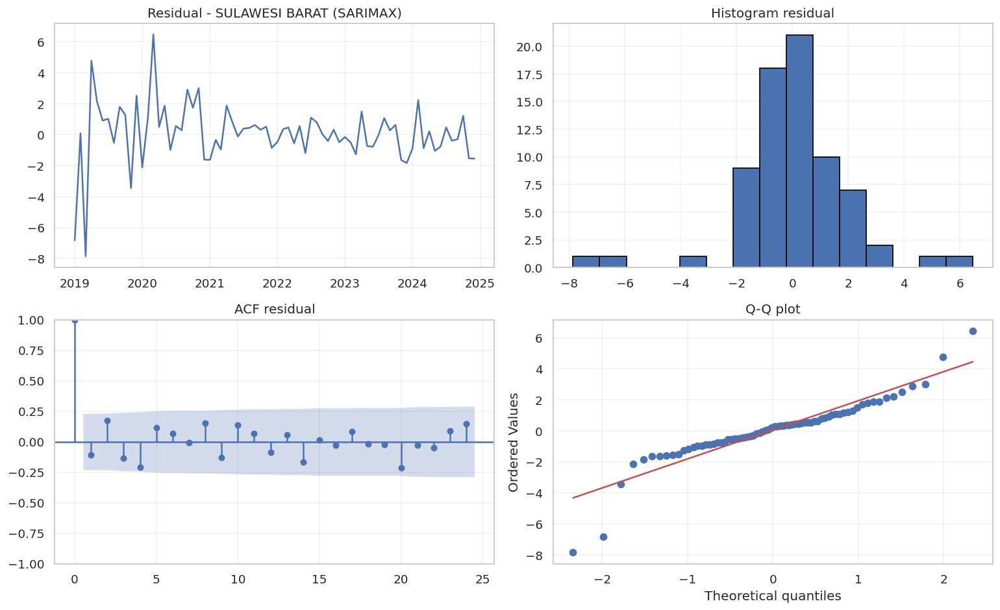

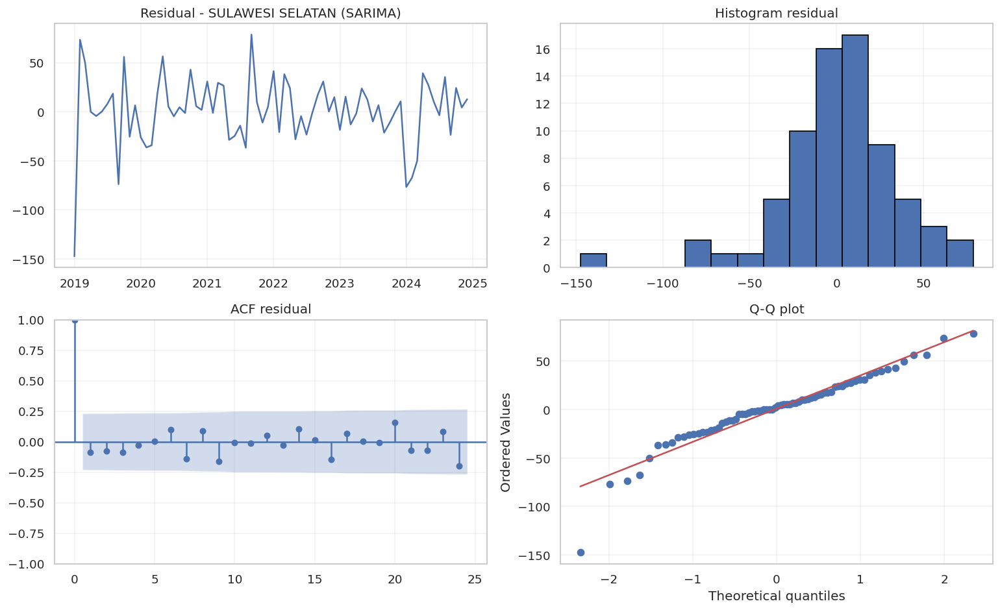

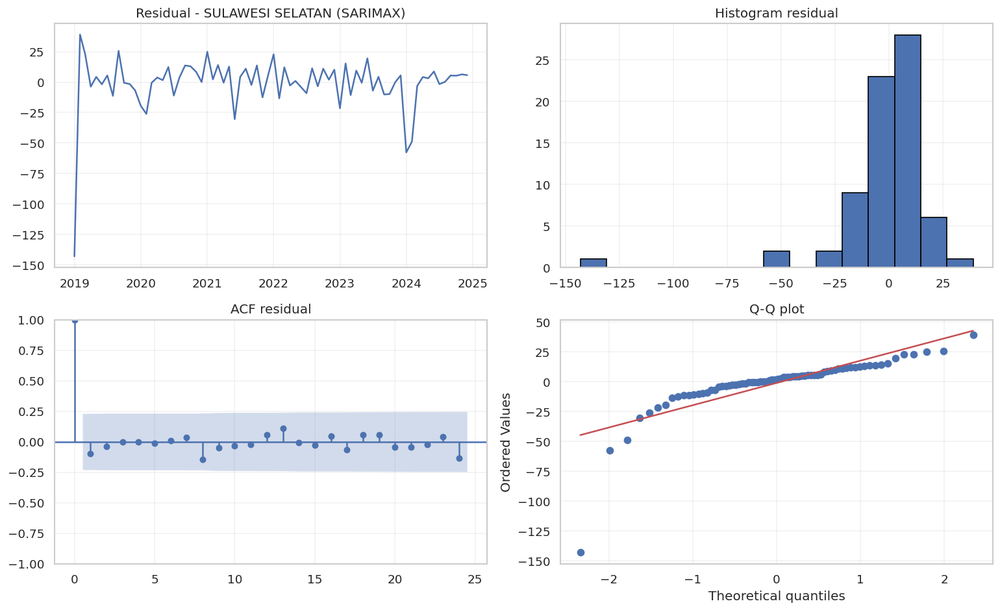

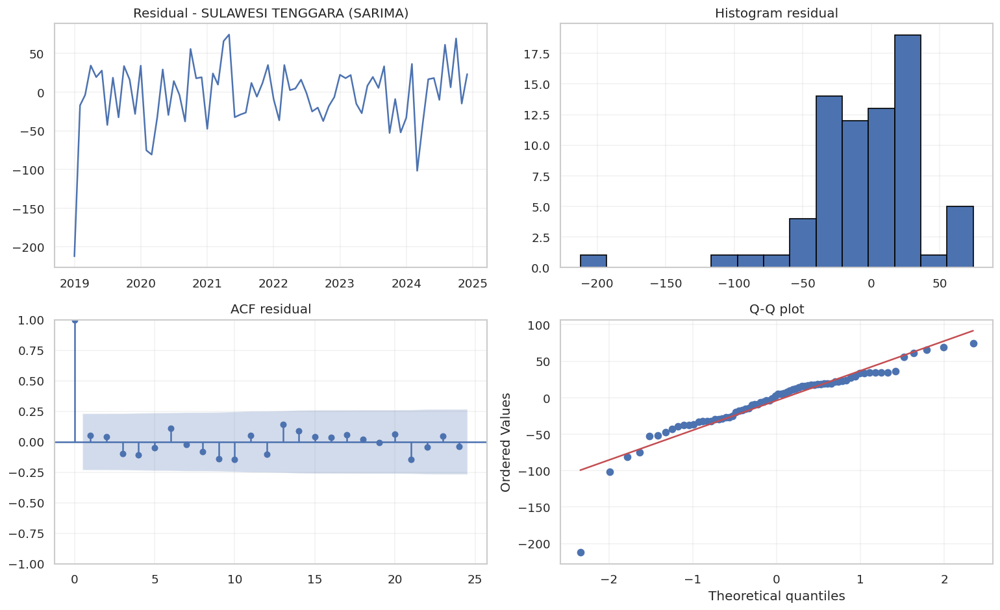

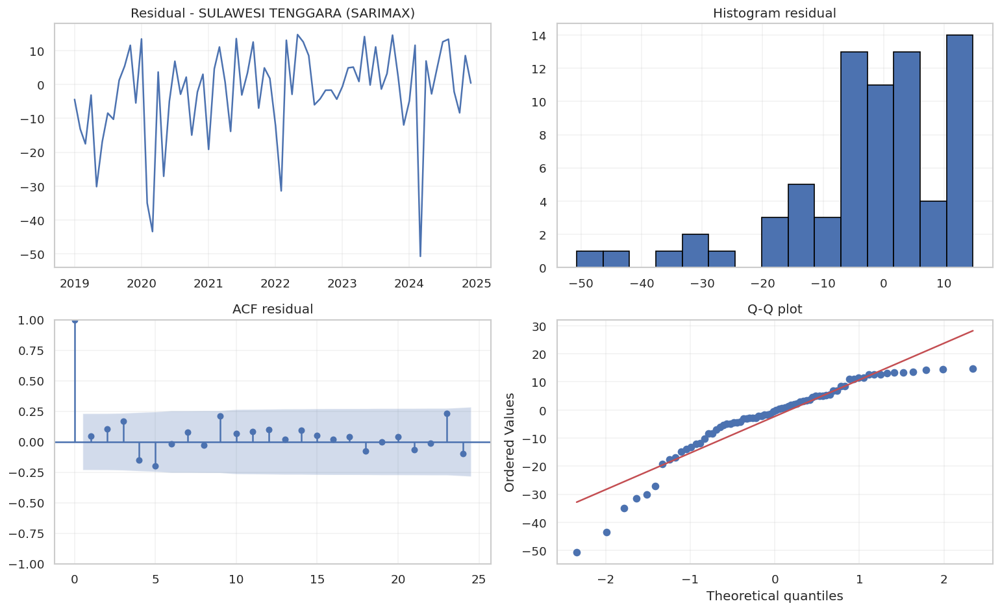

,Provinsi,Model,Ljung-Box lag,Ljung-Box statistic,Ljung-Box p-value,JB statistic,JB p-value,Skewness,Kurtosis,ARCH-LM statistic,ARCH-LM p-value,Autokorelasi residual,Normalitas,Efek ARCH
0,SULAWESI UTARA,SARIMA,12,6.4734,0.8904,4293.4593,0.0000,-5.3379,39.2930,8.4409,0.7498,Tidak terdeteksi,Ditolak,Tidak terdeteksi
1,SULAWESI UTARA,SARIMAX,12,14.0531,0.2973,0.6946,0.7066,0.2263,3.1633,10.5381,0.5689,Tidak terdeteksi,Tidak ditolak,Tidak terdeteksi
2,GORONTALO,SARIMA,12,8.6171,0.7352,1.6484,0.4386,0.2775,3.4914,21.0487,0.0497,Tidak terdeteksi,Tidak ditolak,Terdeteksi
3,GORONTALO,SARIMAX,12,3.1731,0.9942,7.9599,0.0187,-0.7804,3.4658,6.3504,0.8974,Tidak terdeteksi,Ditolak,Tidak terdeteksi
4,SULAWESI TENGAH,SARIMA,12,23.3938,0.0246,1.2583,0.5330,0.0814,2.3732,20.2764,0.0620,Terdeteksi,Tidak ditolak,Tidak terdeteksi
5,SULAWESI TENGAH,SARIMAX,12,16.1741,0.1834,3.0353,0.2192,-0.4391,3.4903,8.0557,0.7808,Tidak terdeteksi,Tidak ditolak,Tidak terdeteksi
6,SULAWESI BARAT,SARIMA,12,10.1870,0.5996,3.7176,0.1559,-0.2010,4.0381,8.8352,0.7169,Tidak terdeteksi,Tidak ditolak,Tidak terdeteksi
7,SULAWESI BARAT,SARIMAX,12,15.3927,0.2207,88.5942,0.0000,-0.7954,8.1962,37.0976,0.0002,Tidak terdeteksi,Ditolak,Terdeteksi
8,SULAWESI SELATAN,SARIMA,12,7.1952,0.8445,52.2427,0.0000,-1.0466,6.6101,10.2621,0.5930,Tidak terdeteksi,Ditolak,Tidak terdeteksi
9,SULAWESI SELATAN,SARIMAX,12,3.4385,0.9916,1402.3656,0.0000,-3.7258,23.2960,19.8214,0.0705,Tidak terdeteksi,Ditolak,Tidak terdeteksi


In [ ]:
hasil_diagnostik = []
residual_model = {}

for prov in PROVINSI_SULAWESI:
    for jenis in ["SARIMA", "SARIMAX"]:
        result = model_terestimasi[(prov, jenis)]
        resid = pd.Series(result.resid).replace([np.inf, -np.inf], np.nan).dropna()
        # Buang observasi awal untuk mengurangi pengaruh inisialisasi state
        resid = resid.iloc[min(S, max(0, len(resid)//4)):]

        lb_lag = min(12, max(1, len(resid)//5))
        lb = acorr_ljungbox(resid, lags=[lb_lag], return_df=True)
        jb_stat, jb_p, jb_skew, jb_kurtosis = jarque_bera(resid)

        arch_lag = min(12, max(1, len(resid)//5))
        arch_stat, arch_p, _, _ = het_arch(resid, nlags=arch_lag)

        residual_model[(prov, jenis)] = resid
        hasil_diagnostik.append({
            "Provinsi": prov,
            "Model": jenis,
            "Ljung-Box lag": lb_lag,
            "Ljung-Box statistic": lb["lb_stat"].iloc[0],
            "Ljung-Box p-value": lb["lb_pvalue"].iloc[0],
            "JB statistic": jb_stat,
            "JB p-value": jb_p,
            "Skewness": jb_skew,
            "Kurtosis": jb_kurtosis,
            "ARCH-LM statistic": arch_stat,
            "ARCH-LM p-value": arch_p,
            "Autokorelasi residual": "Tidak terdeteksi" if lb["lb_pvalue"].iloc[0] > ALPHA else "Terdeteksi",
            "Normalitas": "Tidak ditolak" if jb_p > ALPHA else "Ditolak",
            "Efek ARCH": "Tidak terdeteksi" if arch_p > ALPHA else "Terdeteksi"
        })

        # Plot diagnostik residual
        fig, axes = plt.subplots(2, 2, figsize=(13, 8))
        axes[0,0].plot(resid)
        axes[0,0].set_title(f"Residual - {prov} ({jenis})")
        axes[0,1].hist(resid, bins=15, edgecolor="black")
        axes[0,1].set_title("Histogram residual")
        plot_acf(resid, lags=min(24, len(resid)//2-1), ax=axes[1,0])
        axes[1,0].set_title("ACF residual")
        stats.probplot(resid, dist="norm", plot=axes[1,1])
        axes[1,1].set_title("Q-Q plot")
        plt.tight_layout()
        plt.show()

df_diagnostik = pd.DataFrame(hasil_diagnostik)
display(df_diagnostik.round(4))

## Panduan keputusan diagnostik

| Temuan | Langkah penanganan yang dipertimbangkan |
|---|---|
| Ljung-Box p-value ≤ 0,05 | Periksa ACF residual; tinjau ulang orde `p`, `q`, `P`, `Q` dan spesifikasi musiman. |
| Jarque-Bera p-value ≤ 0,05 | Periksa pencilan dan bentuk distribusi; pertimbangkan transformasi atau distribusi/interval yang lebih sesuai. |
| ARCH-LM p-value ≤ 0,05 | Periksa perubahan varians; pertimbangkan transformasi dan, bila relevan, model ARCH/GARCH pada residual. |

Normalitas residual bukan syarat mutlak untuk menghasilkan titik ramalan, tetapi dapat memengaruhi inferensi dan interval prediksi. Catat hasil yang tidak memenuhi asumsi secara transparan.

# 8. Pemeriksaan Overfitting dengan Penambahan Orde AR dan MA

Pada tahap ini, model terbaik awal dari tahap 5 dikembangkan secara bertahap dengan **menambahkan satu orde AR (p) dan satu orde MA (q) secara bergantian**:

1. Model dasar: orde terbaik hasil identifikasi tahap 5.
2. Kandidat AR: menaikkan `p` satu tingkat, sementara `q`, `d`, `P`, `D`, dan `Q` tetap.
3. Kandidat MA: menaikkan `q` satu tingkat, sementara `p`, `d`, `P`, `D`, dan `Q` tetap.
4. Kandidat gabungan: menaikkan `p` dan `q` masing-masing satu tingkat.

Setiap kandidat diestimasi ulang menggunakan MLE pada data training. Perbandingan menggunakan AIC, BIC, RMSE training, dan RMSE testing. **AIC/BIC training digunakan untuk memilih spesifikasi**; data testing dipakai untuk memeriksa kemampuan generalisasi, bukan untuk terus menambah orde sampai nilai error testing menjadi paling kecil.

Penambahan orde tidak otomatis memperbaiki model. Jika AIC/BIC tidak membaik atau RMSE testing memburuk jauh dibanding training, hal tersebut menjadi indikasi model yang lebih kompleks berisiko overfitting. Batas penambahan orde dibuat maksimal satu tingkat untuk AR dan MA pada tahap pemeriksaan ini.

In [ ]:
# ============================================================
# 8. PEMERIKSAAN OVERFITTING DENGAN PENAMBAHAN ORDE AR/MA
# ============================================================

def rmse(a, f):
    return float(np.sqrt(mean_squared_error(a, f)))

def fit_candidate_for_stage8(prov, jenis, order, seasonal_order):
    """Estimasi kandidat pada data training saja."""
    ytr = y_train_trans[prov]
    ex = exog_train[prov] if jenis == "SARIMAX" else None
    return fit_sarimax(ytr, ex, order, seasonal_order)

hasil_overfit = []
prediksi_holdout = {}
model_seleksi_tahap8 = {}
tabel_perluasan_rows = []

for prov in PROVINSI_SULAWESI:
    tr = train_test[prov]["train"]
    te = train_test[prov]["test"]

    for jenis in ["SARIMA", "SARIMAX"]:

        model_awal = model_terestimasi[(prov, jenis)]
        order_awal = tuple(model_awal.model.order)
        seasonal_awal = tuple(model_awal.model.seasonal_order)

        p0, d0, q0 = order_awal
        P0, D0, Q0, s0 = seasonal_awal

        # Penambahan orde secara bergantian:
        # 1) AR + 1, 2) MA + 1, 3) AR + 1 dan MA + 1.
        daftar_kandidat = [
            ("Model dasar", order_awal),
            ("Tambah AR (p+1)", (p0 + 1, d0, q0)),
            ("Tambah MA (q+1)", (p0, d0, q0 + 1)),
            ("Tambah AR dan MA", (p0 + 1, d0, q0 + 1))
        ]

        kandidat_valid = []

        for nama_kandidat, order_kandidat in daftar_kandidat:
            try:
                if nama_kandidat == "Model dasar":
                    result_kandidat = model_awal
                else:
                    result_kandidat = fit_candidate_for_stage8(
                        prov, jenis, order_kandidat, seasonal_awal
                    )

                # RMSE training pada skala asli
                fitted_bc = np.asarray(result_kandidat.fittedvalues)
                fitted_asli = inverse_y(fitted_bc, prov)
                aktual_train = tr["Y"].values

                mask = np.isfinite(fitted_asli) & np.isfinite(aktual_train)
                rmse_train = rmse(aktual_train[mask], fitted_asli[mask])

                # RMSE testing: hanya untuk penilaian generalisasi
                if jenis == "SARIMA":
                    fc_test = result_kandidat.get_forecast(steps=len(te))
                else:
                    fc_test = result_kandidat.get_forecast(
                        steps=len(te),
                        exog=exog_test[prov]
                    )

                pred_test = inverse_y(fc_test.predicted_mean, prov)
                rmse_test = rmse(te["Y"].values, pred_test)

                konvergen = result_kandidat.mle_retvals.get("converged", False)

                kandidat_valid.append({
                    "nama": nama_kandidat,
                    "result": result_kandidat,
                    "order": order_kandidat,
                    "AIC": result_kandidat.aic,
                    "BIC": result_kandidat.bic,
                    "RMSE training": rmse_train,
                    "RMSE testing": rmse_test,
                    "Konvergen": konvergen
                })

                tabel_perluasan_rows.append({
                    "Provinsi": prov,
                    "Model": jenis,
                    "Kandidat": nama_kandidat,
                    "Order": str(order_kandidat),
                    "Seasonal order": str(seasonal_awal),
                    "AIC": result_kandidat.aic,
                    "BIC": result_kandidat.bic,
                    "RMSE training": rmse_train,
                    "RMSE testing": rmse_test,
                    "Konvergen": konvergen
                })

            except Exception as e:
                print(
                    f"Kandidat gagal: {prov} - {jenis} - "
                    f"{nama_kandidat}: {e}"
                )

        if not kandidat_valid:
            raise RuntimeError(f"Semua kandidat gagal pada {prov} - {jenis}")

        # Pemilihan berdasarkan AIC training, bukan RMSE testing.
        # Jika AIC sama, pilih BIC yang lebih kecil.
        kandidat_valid.sort(key=lambda x: (x["AIC"], x["BIC"]))
        terpilih = kandidat_valid[0]

        model_seleksi_tahap8[(prov, jenis)] = terpilih["result"]
        prediksi_holdout[(prov, jenis)] = pd.Series(
            inverse_y(
                terpilih["result"].get_forecast(
                    steps=len(te),
                    **({"exog": exog_test[prov]} if jenis == "SARIMAX" else {})
                ).predicted_mean,
                prov
            ),
            index=te.index
        )

        rasio = (
            terpilih["RMSE testing"] / terpilih["RMSE training"]
            if terpilih["RMSE training"] > 0 else np.nan
        )

        hasil_overfit.append({
            "Provinsi": prov,
            "Model": jenis,
            "Model terpilih tahap 8": terpilih["nama"],
            "Order terpilih": str(terpilih["order"]),
            "AIC": terpilih["AIC"],
            "BIC": terpilih["BIC"],
            "RMSE training": terpilih["RMSE training"],
            "RMSE testing": terpilih["RMSE testing"],
            "Rasio testing/training": rasio,
            "Catatan": (
                "Periksa kemungkinan overfitting"
                if rasio > 2
                else "Tidak ada indikasi kuat berdasarkan rasio RMSE"
            )
        })

        print(
            f"{prov} | {jenis} | terpilih: {terpilih['nama']} | "
            f"order={terpilih['order']} | "
            f"AIC={terpilih['AIC']:.3f}"
        )

        # Gunakan model terpilih tahap 8 untuk tahap berikutnya
        model_terestimasi[(prov, jenis)] = terpilih["result"]

# Tabel seluruh kandidat perluasan AR/MA
df_perluasan = pd.DataFrame(tabel_perluasan_rows)
print("PERBANDINGAN MODEL DASAR DAN MODEL DENGAN PENAMBAHAN AR/MA")
display(
    df_perluasan.sort_values(["Provinsi", "Model", "AIC"]).round(4)
)

# Ringkasan pemeriksaan overfitting
df_overfit = pd.DataFrame(hasil_overfit)
print("RINGKASAN PEMERIKSAAN OVERFITTING")
display(df_overfit.round(4))

SULAWESI UTARA | SARIMA | terpilih: Model dasar | order=(2, 1, 1) | AIC=-32.835
SULAWESI UTARA | SARIMAX | terpilih: Tambah AR dan MA | order=(2, 1, 3) | AIC=-238.309
GORONTALO | SARIMA | terpilih: Tambah MA (q+1) | order=(2, 0, 3) | AIC=621.445


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


GORONTALO | SARIMAX | terpilih: Tambah AR dan MA | order=(3, 0, 3) | AIC=464.447
SULAWESI TENGAH | SARIMA | terpilih: Model dasar | order=(0, 0, 2) | AIC=775.604
SULAWESI TENGAH | SARIMAX | terpilih: Tambah MA (q+1) | order=(0, 0, 3) | AIC=613.275
SULAWESI BARAT | SARIMA | terpilih: Tambah MA (q+1) | order=(2, 1, 3) | AIC=394.662
SULAWESI BARAT | SARIMAX | terpilih: Tambah MA (q+1) | order=(1, 1, 3) | AIC=252.168
SULAWESI SELATAN | SARIMA | terpilih: Tambah MA (q+1) | order=(0, 1, 3) | AIC=653.542
SULAWESI SELATAN | SARIMAX | terpilih: Tambah MA (q+1) | order=(0, 1, 3) | AIC=562.368
SULAWESI TENGGARA | SARIMA | terpilih: Tambah MA (q+1) | order=(1, 0, 3) | AIC=693.355
SULAWESI TENGGARA | SARIMAX | terpilih: Tambah MA (q+1) | order=(0, 0, 3) | AIC=563.693
PERBANDINGAN MODEL DASAR DAN MODEL DENGAN PENAMBAHAN AR/MA


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Provinsi,Model,Kandidat,Order,Seasonal order,AIC,BIC,RMSE training,RMSE testing,Konvergen
10,GORONTALO,SARIMA,Tambah MA (q+1),"(2, 0, 3)","(1, 0, 1, 12)",621.4448,641.4204,11876.9358,13453.1079,True
11,GORONTALO,SARIMA,Tambah AR dan MA,"(3, 0, 3)","(1, 0, 1, 12)",622.7308,644.9259,11301.0069,13302.8848,True
9,GORONTALO,SARIMA,Tambah AR (p+1),"(3, 0, 2)","(1, 0, 1, 12)",628.6580,648.7649,11442.4231,12832.5215,True
8,GORONTALO,SARIMA,Model dasar,"(2, 0, 2)","(1, 0, 1, 12)",629.5451,647.4180,12155.5288,12683.6800,True
15,GORONTALO,SARIMAX,Tambah AR dan MA,"(3, 0, 3)","(0, 0, 1, 12)",464.4472,488.8617,8454.2738,3597.3370,True
14,GORONTALO,SARIMAX,Tambah MA (q+1),"(2, 0, 3)","(0, 0, 1, 12)",466.1594,488.3545,5691.2184,3362.4236,False
12,GORONTALO,SARIMAX,Model dasar,"(2, 0, 2)","(0, 0, 1, 12)",470.5715,490.6785,5921.4533,3446.9773,True
13,GORONTALO,SARIMAX,Tambah AR (p+1),"(3, 0, 2)","(0, 0, 1, 12)",472.2431,494.5841,6098.7883,3402.8901,True
26,SULAWESI BARAT,SARIMA,Tambah MA (q+1),"(2, 1, 3)","(1, 0, 1, 12)",394.6616,412.2991,15158.8867,14612.2427,True
27,SULAWESI BARAT,SARIMA,Tambah AR dan MA,"(3, 1, 3)","(1, 0, 1, 12)",395.4680,415.3102,16840.1790,14486.7035,True


RINGKASAN PEMERIKSAAN OVERFITTING


,Provinsi,Model,Model terpilih tahap 8,Order terpilih,AIC,BIC,RMSE training,RMSE testing,Rasio testing/training,Catatan
0,SULAWESI UTARA,SARIMA,Model dasar,"(2, 1, 1)",-32.8346,-19.4299,67344.8633,4483.6344,0.0666,Tidak ada indikasi kuat berdasarkan rasio RMSE
1,SULAWESI UTARA,SARIMAX,Tambah AR dan MA,"(2, 1, 3)",-238.3086,-219.3530,23803.8807,2236.3350,0.0939,Tidak ada indikasi kuat berdasarkan rasio RMSE
2,GORONTALO,SARIMA,Tambah MA (q+1),"(2, 0, 3)",621.4448,641.4204,11876.9358,13453.1079,1.1327,Tidak ada indikasi kuat berdasarkan rasio RMSE
3,GORONTALO,SARIMAX,Tambah AR dan MA,"(3, 0, 3)",464.4472,488.8617,8454.2738,3597.3370,0.4255,Tidak ada indikasi kuat berdasarkan rasio RMSE
4,SULAWESI TENGAH,SARIMA,Model dasar,"(0, 0, 2)",775.6043,789.0090,33682.5245,24695.9820,0.7332,Tidak ada indikasi kuat berdasarkan rasio RMSE
5,SULAWESI TENGAH,SARIMAX,Tambah MA (q+1),"(0, 0, 3)",613.2750,631.0311,5254.0138,5530.6494,1.0527,Tidak ada indikasi kuat berdasarkan rasio RMSE
6,SULAWESI BARAT,SARIMA,Tambah MA (q+1),"(2, 1, 3)",394.6616,412.2991,15158.8867,14612.2427,0.9639,Tidak ada indikasi kuat berdasarkan rasio RMSE
7,SULAWESI BARAT,SARIMAX,Tambah MA (q+1),"(1, 1, 3)",252.1683,272.0105,11634.0750,3931.7237,0.3379,Tidak ada indikasi kuat berdasarkan rasio RMSE
8,SULAWESI SELATAN,SARIMA,Tambah MA (q+1),"(0, 1, 3)",653.5416,666.7697,190661.4233,162228.8715,0.8509,Tidak ada indikasi kuat berdasarkan rasio RMSE
9,SULAWESI SELATAN,SARIMAX,Tambah MA (q+1),"(0, 1, 3)",562.3678,580.0053,83260.6593,75108.3950,0.9021,Tidak ada indikasi kuat berdasarkan rasio RMSE


# 9. Evaluasi dan Perbandingan Model SARIMA dan SARIMAX

Kedua model (setelah pemeriksaan perluasan orde AR/MA pada tahap 8) dievaluasi pada periode testing yang sama menggunakan RMSE, MAE, dan MAPE. MAPE dihitung hanya pada observasi aktual yang tidak sama dengan nol. Karena SARIMAX menggunakan X1 dan X2 aktual pada periode testing, hasil ini mengukur akurasi kondisional; untuk penggunaan operasional, nilai eksogen masa depan harus tersedia atau diramalkan.

,Provinsi,Model,RMSE,MAE,MAPE (%),AIC training,BIC training
0,SULAWESI UTARA,SARIMA,4483.6344,3503.7412,15.8126,-32.8346,-19.4299
1,SULAWESI UTARA,SARIMAX,2236.3350,1553.4032,6.5024,-238.3086,-219.3530
2,GORONTALO,SARIMA,13453.1079,10263.4439,61.9242,621.4448,641.4204
3,GORONTALO,SARIMAX,3597.3370,3053.6445,15.2898,464.4472,488.8617
4,SULAWESI TENGAH,SARIMA,24695.9820,17829.3313,23.9546,775.6043,789.0090
5,SULAWESI TENGAH,SARIMAX,5530.6494,4965.4278,7.4078,613.2750,631.0311
6,SULAWESI BARAT,SARIMA,14612.2427,11176.7140,30.1680,394.6616,412.2991
7,SULAWESI BARAT,SARIMAX,3931.7237,3219.6789,10.0238,252.1683,272.0105
8,SULAWESI SELATAN,SARIMA,162228.8715,113180.3702,26.2412,653.5416,666.7697
9,SULAWESI SELATAN,SARIMAX,75108.3950,50804.8752,13.1367,562.3678,580.0053


,Provinsi,Model terbaik berdasarkan RMSE testing
0,SULAWESI UTARA,SARIMAX
1,GORONTALO,SARIMAX
2,SULAWESI TENGAH,SARIMAX
3,SULAWESI BARAT,SARIMAX
4,SULAWESI SELATAN,SARIMAX
5,SULAWESI TENGGARA,SARIMAX


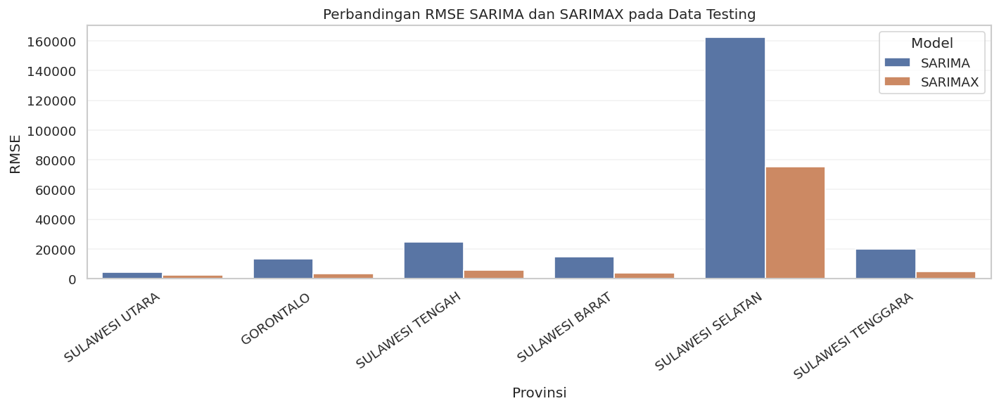

In [ ]:
def hitung_metrik(actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    mask = np.abs(actual) > 1e-10
    return {
        "RMSE": rmse(actual, pred),
        "MAE": float(mean_absolute_error(actual, pred)),
        "MAPE (%)": float(np.mean(np.abs((actual[mask]-pred[mask])/actual[mask]))*100) if mask.any() else np.nan
    }

evaluasi_rows = []
for prov in PROVINSI_SULAWESI:
    actual = train_test[prov]["test"]["Y"].values
    for jenis in ["SARIMA", "SARIMAX"]:
        pred = prediksi_holdout[(prov, jenis)].values
        evaluasi_rows.append({
            "Provinsi": prov,
            "Model": jenis,
            **hitung_metrik(actual, pred),
            "AIC training": model_terestimasi[(prov, jenis)].aic,
            "BIC training": model_terestimasi[(prov, jenis)].bic
        })

df_evaluasi = pd.DataFrame(evaluasi_rows)
display(df_evaluasi.round(4))

# Model terbaik per provinsi berdasarkan RMSE testing
model_terbaik = {}
for prov in PROVINSI_SULAWESI:
    sub = df_evaluasi[df_evaluasi["Provinsi"] == prov]
    pemenang = sub.loc[sub["RMSE"].idxmin(), "Model"]
    model_terbaik[prov] = pemenang

display(pd.DataFrame({
    "Provinsi": PROVINSI_SULAWESI,
    "Model terbaik berdasarkan RMSE testing": [model_terbaik[p] for p in PROVINSI_SULAWESI]
}))

# Grafik perbandingan RMSE per provinsi
plt.figure(figsize=(12, 5))
sns.barplot(data=df_evaluasi, x="Provinsi", y="RMSE", hue="Model")
plt.title("Perbandingan RMSE SARIMA dan SARIMAX pada Data Testing")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# 10. Forecasting dan Plot Perbandingan Aktual dengan Prediksi

Pertama ditampilkan perbandingan aktual dan prediksi pada data testing menggunakan grafik Plotly interaktif. Grafik forecast masa depan juga dilengkapi hover, zoom, range slider, dan interval prediksi. Setelah itu model terbaik per provinsi diestimasi ulang menggunakan seluruh data yang tersedia untuk meramalkan 12 bulan berikutnya.

**Catatan SARIMAX:** X1 dan X2 masa depan tidak diketahui dari dataset. Untuk ilustrasi forecast 12 bulan ke depan, notebook menggunakan rata-rata historis per bulan dari 36 bulan terakhir sebagai asumsi nilai eksogen. Hasil forecast SARIMAX bergantung pada asumsi tersebut.

10.1 AKTUAL VS PREDIKSI DATA TESTING


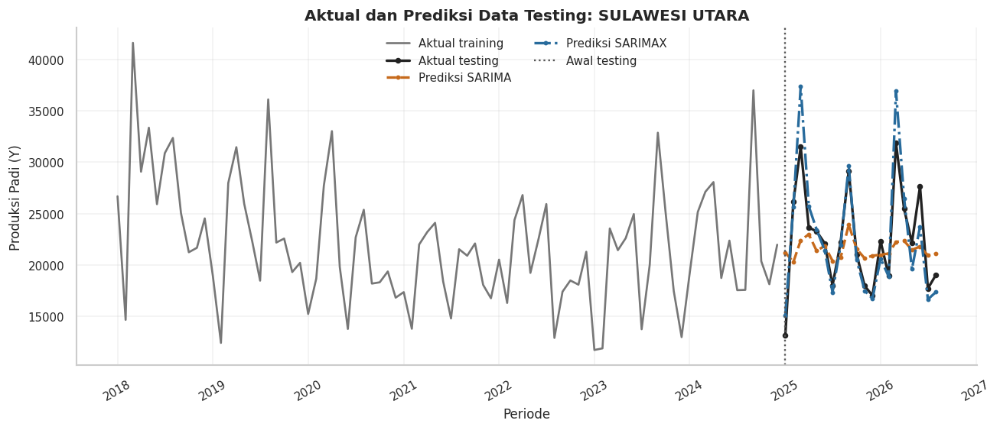

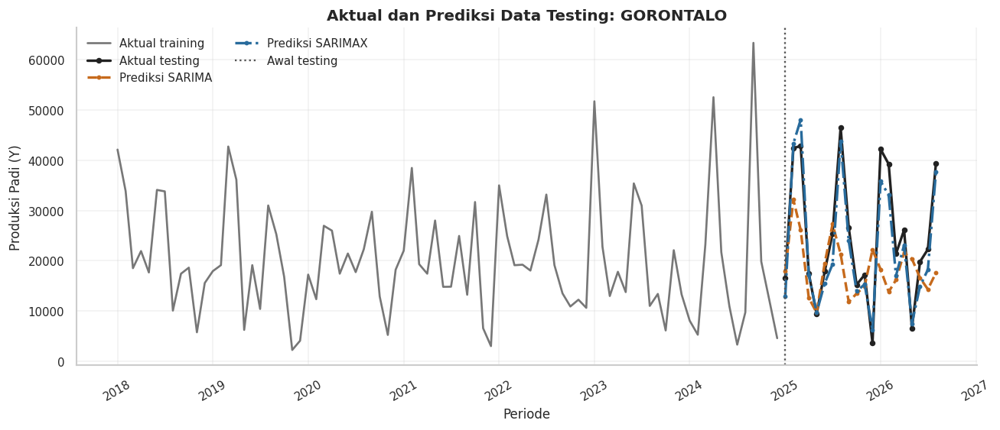

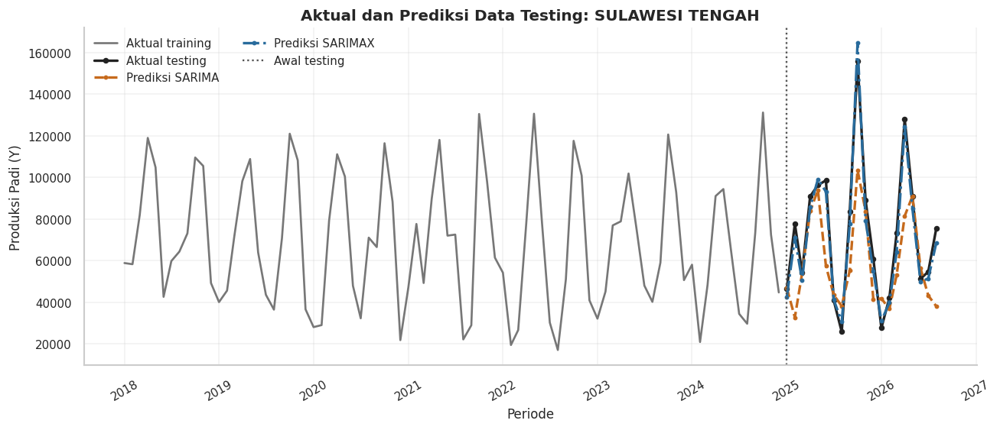

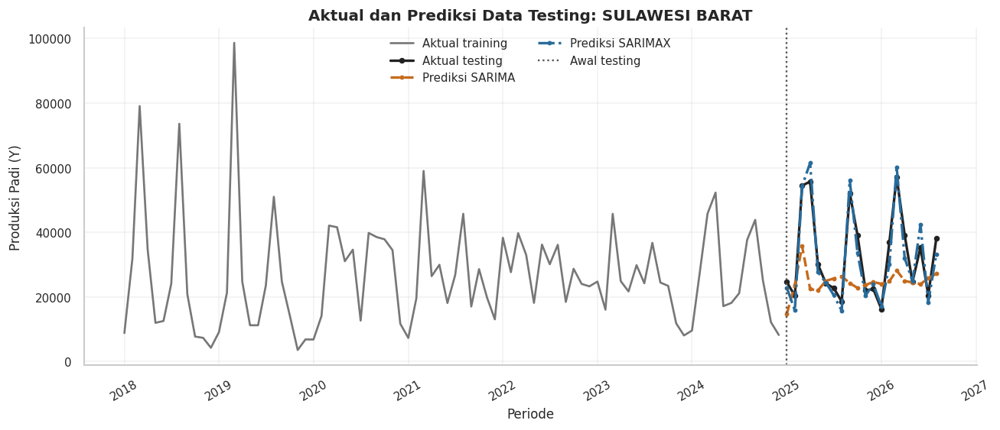

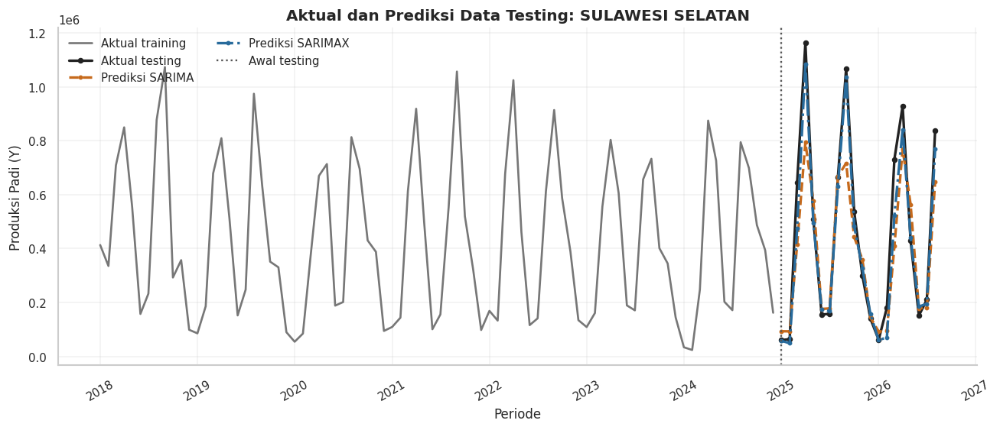

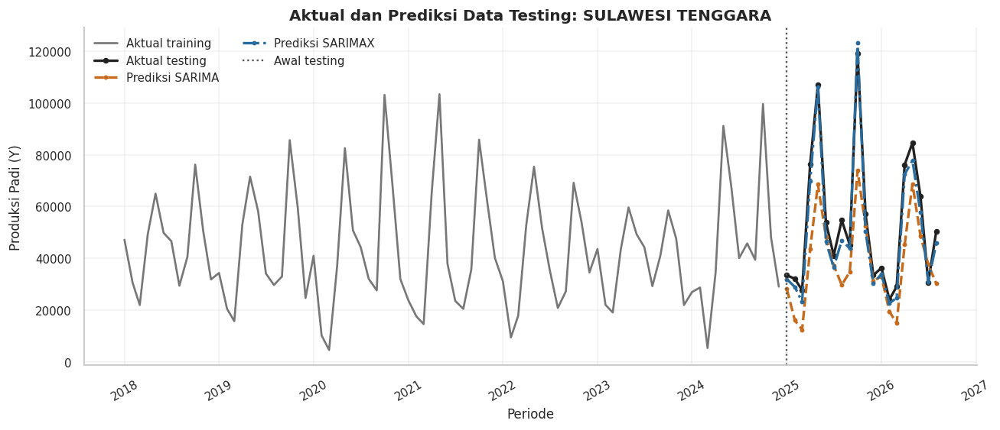


10.2 FORECAST 12 BULAN MASA DEPAN
SULAWESI UTARA: SARIMAX | Forecast 12 bulan selesai.
GORONTALO: SARIMAX | Forecast 12 bulan selesai.
SULAWESI TENGAH: SARIMAX | Forecast 12 bulan selesai.
SULAWESI BARAT: SARIMAX | Forecast 12 bulan selesai.
SULAWESI SELATAN: SARIMAX | Forecast 12 bulan selesai.
SULAWESI TENGGARA: SARIMAX | Forecast 12 bulan selesai.

10.3 VISUALISASI FORECAST MASA DEPAN


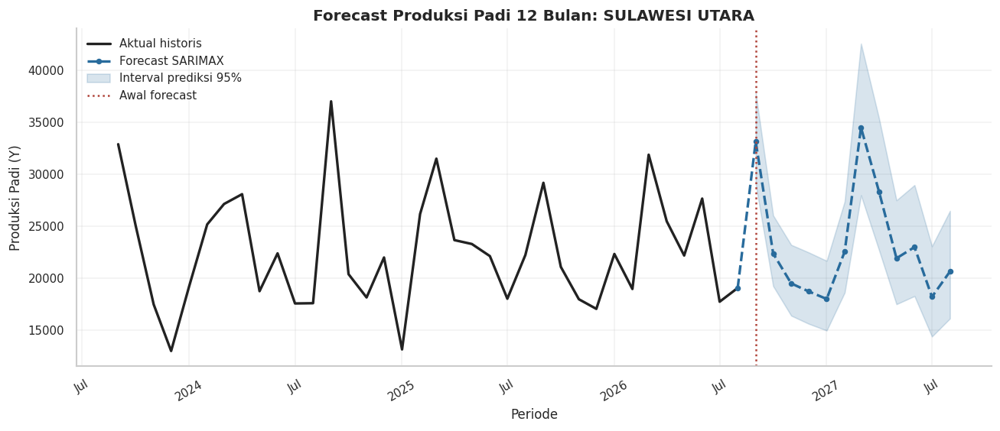

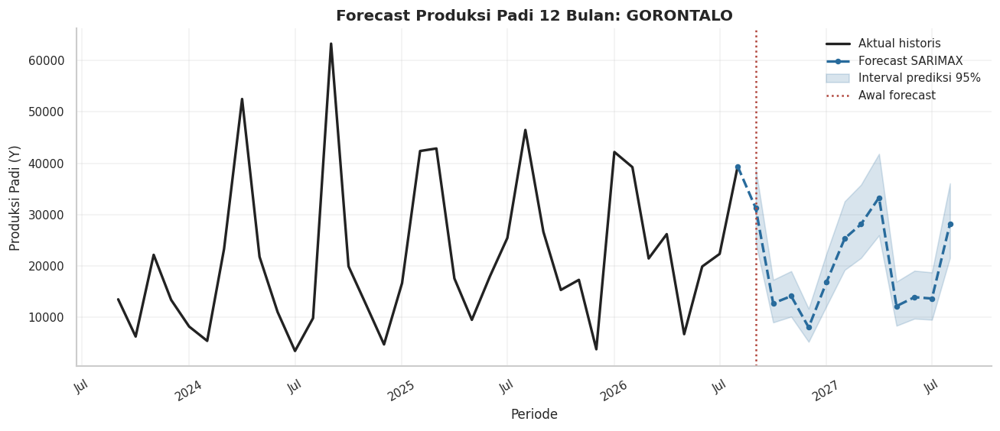

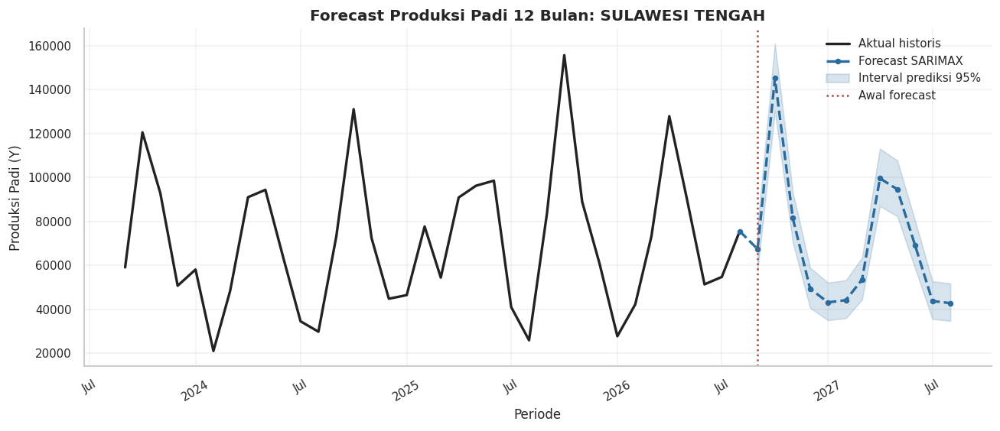

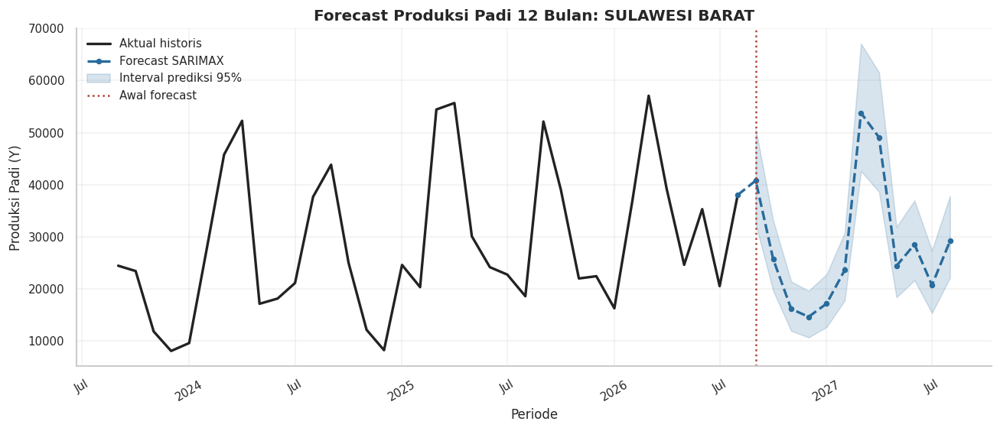

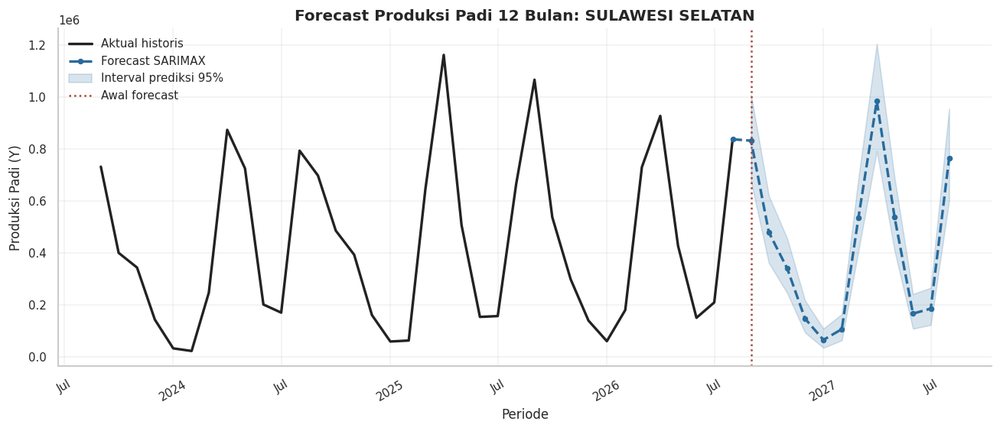

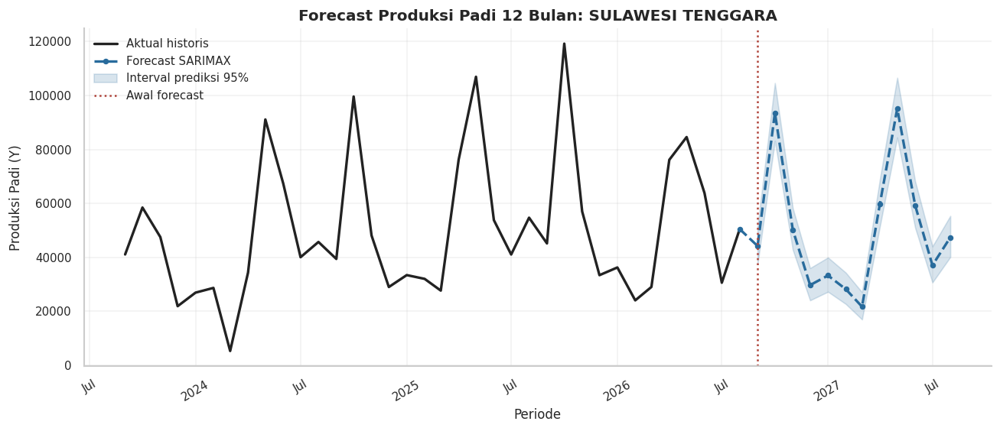


10.4 HASIL FORECAST PRODUKSI PADI


Aktual  Prediksi  Batas bawah 95%  \
Provinsi          Tanggal                                         
SULAWESI UTARA    2026-09-01     NaN  33127.06         29043.98   
                  2026-10-01     NaN  22350.33         19214.43   
                  2026-11-01     NaN  19469.94         16367.44   
                  2026-12-01     NaN  18701.60         15588.53   
                  2027-01-01     NaN  17972.84         14937.79   
...                              ...       ...              ...   
SULAWESI TENGGARA 2027-04-01     NaN  59904.98         51554.43   
                  2027-05-01     NaN  95178.47         84452.71   
                  2027-06-01     NaN  59331.26         51069.56   
                  2027-07-01     NaN  37068.23         30709.28   
                  2027-08-01     NaN  47431.73         40135.66   

                              Batas atas 95%    Model  
Provinsi          Tanggal                              
SULAWESI UTARA    2026-09-01        37799.57  SARIMAX  
                  2026-10-01        26012.05  SARIMAX  
                  2026-11-01        23177.04  SARIMAX  
                  2026-12-01        22453.95  SARIMAX  
                  2027-01-01        21642.05  SARIMAX  
...                                      ...      ...  
SULAWESI TENGGARA 2027-04-01        68930.19  SARIMAX  
                  2027-05-01       106593.78  SARIMAX  
                  2027-06-01        68259.67  SARIMAX  
                  2027-07-01        44071.89  SARIMAX  
                  2027-08-01        55383.95  SARIMAX  

[72 rows x 5 columns]


File Excel berhasil dibuat: Forecast_Padi_Sulawesi_12_Bulan.xlsx
Folder grafik: Grafik_Jurnal_Sulawesi
Seluruh visualisasi telah disimpan sebagai PNG dan PDF.


In [ ]:

# ============================================================
# 10. VISUALISASI STATIS DAN FORECAST PRODUKSI PADI
# SARIMA DAN SARIMAX - ENAM PROVINSI DI PULAU SULAWESI
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display

# ============================================================
# 10.0 KONFIGURASI GRAFIK UNTUK JURNAL
# ============================================================

HORIZON_TEST = 20
HORIZON_FORECAST = 12

FOLDER_GRAFIK = "Grafik_Jurnal_Sulawesi"
os.makedirs(FOLDER_GRAFIK, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 4.8),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25
})


def format_tanggal(ax):
    """Mengatur format tanggal grafik."""
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )
    ax.tick_params(axis="x", rotation=30)


def simpan_grafik(fig, nama_file):
    """Menyimpan grafik statis dalam PNG dan PDF."""
    nama_aman = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        str(nama_file)
    )

    fig.savefig(
        os.path.join(
            FOLDER_GRAFIK,
            f"{nama_aman}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        os.path.join(
            FOLDER_GRAFIK,
            f"{nama_aman}.pdf"
        ),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 10.1 AKTUAL VS PREDIKSI PADA DATA TESTING
# ============================================================

print("=" * 70)
print("10.1 AKTUAL VS PREDIKSI DATA TESTING")
print("=" * 70)

for prov in PROVINSI_SULAWESI:

    tr = train_test[prov]["train"]
    te = train_test[prov]["test"]

    if len(te) != HORIZON_TEST:
        raise ValueError(
            f"Testing {prov} berisi {len(te)} observasi, "
            f"bukan {HORIZON_TEST}. "
            "Jalankan ulang pembagian data dan pemodelan."
        )

    fig, ax = plt.subplots(figsize=(11, 4.8))

    # Aktual training
    ax.plot(
        tr.index,
        tr["Y"],
        color="#777777",
        linewidth=1.6,
        label="Aktual training"
    )

    # Aktual testing
    ax.plot(
        te.index,
        te["Y"],
        color="#222222",
        linewidth=2.0,
        marker="o",
        markersize=3.5,
        label="Aktual testing"
    )

    # Prediksi SARIMA dan SARIMAX
    for jenis, warna, gaya in [
        ("SARIMA", "#C66A1C", "--"),
        ("SARIMAX", "#286B9C", "-.")
    ]:

        pred = np.asarray(
            prediksi_holdout[(prov, jenis)],
            dtype=float
        ).reshape(-1)

        if len(pred) != len(te):
            raise ValueError(
                f"Panjang prediksi {jenis} pada {prov} "
                f"adalah {len(pred)}, sedangkan "
                f"testing berisi {len(te)} observasi."
            )

        ax.plot(
            te.index,
            pred,
            color=warna,
            linestyle=gaya,
            linewidth=2,
            marker=".",
            markersize=5,
            label=f"Prediksi {jenis}"
        )

    # Penanda awal testing
    ax.axvline(
        te.index[0],
        color="#555555",
        linestyle=":",
        linewidth=1.4,
        label="Awal testing"
    )

    ax.set_title(
        f"Aktual dan Prediksi Data Testing: {prov}",
        fontweight="bold"
    )
    ax.set_xlabel("Periode")
    ax.set_ylabel("Produksi Padi (Y)")
    ax.grid(alpha=0.25)

    ax.legend(
        loc="best",
        ncol=2,
        frameon=False
    )

    format_tanggal(ax)
    fig.tight_layout()

    simpan_grafik(
        fig,
        f"Testing_SARIMA_SARIMAX_{prov}"
    )


# ============================================================
# 10.2 FORECAST 12 BULAN SETELAH OBSERVASI TERAKHIR
# ============================================================

print("\n" + "=" * 70)
print("10.2 FORECAST 12 BULAN MASA DEPAN")
print("=" * 70)

hasil_forecast = {}
model_final = {}
eksogen_future = {}

for prov in PROVINSI_SULAWESI:

    seluruh = seri[prov].copy().sort_index()
    jenis = model_terbaik[prov]

    # Tanggal forecast setiap provinsi
    tanggal_terakhir = seluruh.index.max()

    idx_future = pd.date_range(
        start=(
            tanggal_terakhir
            + pd.offsets.MonthBegin(1)
        ),
        periods=HORIZON_FORECAST,
        freq="MS"
    )

    # Transformasi Y menggunakan parameter Box-Cox
    # yang telah diestimasi pada data training
    y_full = transform_y(
        seluruh["Y"],
        prov
    )

    # --------------------------------------------------------
    # PERSIAPAN VARIABEL EKSOGEN SARIMAX
    # --------------------------------------------------------

    if jenis == "SARIMAX":

        mean_x = seluruh[EXOG].mean()

        std_x = (
            seluruh[EXOG]
            .std()
            .replace(0, 1)
            .fillna(1)
        )

        # Standardisasi eksogen seluruh observasi
        ex_full = (
            seluruh[EXOG] - mean_x
        ) / std_x

        # Asumsi eksogen masa depan:
        # rata-rata bulanan dari 36 observasi terakhir
        hist_x = seluruh[EXOG].iloc[-36:]

        future_raw = pd.DataFrame(
            index=idx_future,
            columns=EXOG,
            dtype=float
        )

        for col in EXOG:

            rata_bulan = (
                hist_x[col]
                .groupby(hist_x.index.month)
                .mean()
            )

            rata_keseluruhan = hist_x[col].mean()

            future_raw[col] = [
                rata_bulan.get(bulan, np.nan)
                for bulan in idx_future.month
            ]

            future_raw[col] = (
                future_raw[col]
                .fillna(rata_keseluruhan)
            )

        ex_future = (
            future_raw - mean_x
        ) / std_x

        eksogen_future[prov] = future_raw.copy()

    else:

        ex_full = None
        ex_future = None

    # --------------------------------------------------------
    # MENGAMBIL ORDE MODEL TERBAIK
    # --------------------------------------------------------

    model_awal = model_terestimasi[
        (prov, jenis)
    ]

    order = model_awal.model.order

    seasonal_order = (
        model_awal.model.seasonal_order
    )

    # --------------------------------------------------------
    # REFIT MENGGUNAKAN SELURUH DATA
    # --------------------------------------------------------

    final_model = fit_sarimax(
        y_full,
        ex_full,
        order,
        seasonal_order
    )

    # --------------------------------------------------------
    # FORECAST 12 BULAN
    # --------------------------------------------------------

    fc = final_model.get_forecast(
        steps=HORIZON_FORECAST,
        exog=ex_future
    )

    ci = fc.conf_int(alpha=0.05)

    # Invers Box-Cox ke skala produksi padi
    prediksi = np.asarray(
        inverse_y(fc.predicted_mean, prov),
        dtype=float
    )

    batas_bawah = np.asarray(
        inverse_y(ci.iloc[:, 0], prov),
        dtype=float
    )

    batas_atas = np.asarray(
        inverse_y(ci.iloc[:, 1], prov),
        dtype=float
    )

    # --------------------------------------------------------
    # MENYIMPAN HASIL FORECAST
    # --------------------------------------------------------

    hasil_forecast[prov] = pd.DataFrame({
        "Aktual": np.nan,
        "Prediksi": prediksi,
        "Batas bawah 95%": batas_bawah,
        "Batas atas 95%": batas_atas,
        "Model": jenis
    }, index=idx_future)

    hasil_forecast[prov].index.name = "Tanggal"

    model_final[prov] = final_model

    print(
        f"{prov}: {jenis} | "
        f"Forecast {HORIZON_FORECAST} bulan selesai."
    )


# ============================================================
# 10.3 GRAFIK FORECAST STATIS UNTUK JURNAL
# ============================================================

print("\n" + "=" * 70)
print("10.3 VISUALISASI FORECAST MASA DEPAN")
print("=" * 70)

for prov in PROVINSI_SULAWESI:

    historis = (
        seri[prov]["Y"]
        .sort_index()
        .iloc[-36:]
    )

    ramalan = hasil_forecast[prov]

    fig, ax = plt.subplots(figsize=(11, 4.8))

    # --------------------------------------------------------
    # DATA AKTUAL HISTORIS
    # --------------------------------------------------------

    ax.plot(
        historis.index,
        historis.values,
        color="#222222",
        linewidth=2,
        label="Aktual historis"
    )

    # --------------------------------------------------------
    # GARIS FORECAST
    # --------------------------------------------------------

    # Menghubungkan titik aktual terakhir
    # dengan prediksi pertama untuk visualisasi
    tanggal_grafik = (
        [historis.index[-1]]
        + list(ramalan.index)
    )

    nilai_grafik = np.concatenate([
        [float(historis.iloc[-1])],
        ramalan["Prediksi"].to_numpy(dtype=float)
    ])

    ax.plot(
        tanggal_grafik,
        nilai_grafik,
        color="#286B9C",
        linestyle="--",
        linewidth=2,
        marker="o",
        markersize=3.5,
        label=f"Forecast {model_terbaik[prov]}"
    )

    # --------------------------------------------------------
    # INTERVAL PREDIKSI 95%
    # --------------------------------------------------------

    ax.fill_between(
        ramalan.index,
        ramalan["Batas bawah 95%"].to_numpy(
            dtype=float
        ),
        ramalan["Batas atas 95%"].to_numpy(
            dtype=float
        ),
        color="#286B9C",
        alpha=0.18,
        label="Interval prediksi 95%"
    )

    # --------------------------------------------------------
    # PENANDA AWAL FORECAST
    # --------------------------------------------------------

    ax.axvline(
        ramalan.index[0],
        color="#B0443A",
        linestyle=":",
        linewidth=1.5,
        label="Awal forecast"
    )

    # --------------------------------------------------------
    # FORMAT GRAFIK
    # --------------------------------------------------------

    ax.set_title(
        f"Forecast Produksi Padi "
        f"{HORIZON_FORECAST} Bulan: {prov}",
        fontweight="bold"
    )

    ax.set_xlabel("Periode")
    ax.set_ylabel("Produksi Padi (Y)")

    ax.grid(alpha=0.25)

    ax.legend(
        loc="best",
        frameon=False,
        fontsize=9
    )

    format_tanggal(ax)
    fig.tight_layout()

    simpan_grafik(
        fig,
        f"Forecast_{prov}"
    )


# ============================================================
# 10.4 TABEL HASIL FORECAST SELURUH PROVINSI
# ============================================================

tabel_forecast = pd.concat(
    {
        prov: hasil_forecast[prov]
        for prov in PROVINSI_SULAWESI
    },
    names=["Provinsi", "Tanggal"]
)

print("\n" + "=" * 70)
print("10.4 HASIL FORECAST PRODUKSI PADI")
print("=" * 70)

display(tabel_forecast.round(2))

# ============================================================
# 10.5 EKSPOR TABEL FORECAST KE EXCEL
# ============================================================

nama_excel = "Forecast_Padi_Sulawesi_12_Bulan.xlsx"

tabel_forecast.reset_index().to_excel(
    nama_excel,
    index=False
)

print("\nFile Excel berhasil dibuat:", nama_excel)
print("Folder grafik:", FOLDER_GRAFIK)
print("Seluruh visualisasi telah disimpan sebagai PNG dan PDF.")


## Simpan hasil analisis ke Excel

File keluaran berisi tabel Box-Cox, hasil ADF, kandidat model, estimasi parameter, diagnostik residual, perluasan orde AR/MA tahap 8, overfitting, evaluasi hold-out, serta hasil forecasting.

In [ ]:

# ============================================================
# 11. EKSPOR SELURUH HASIL ANALISIS SARIMA DAN SARIMAX
# ENAM PROVINSI DI PULAU SULAWESI
#
# OUTPUT:
# 1. Excel seluruh hasil analisis
# 2. Seluruh grafik PNG (300 dpi)
# 3. Seluruh grafik PDF
# 4. ZIP yang langsung diunduh
#
# TANPA GOOGLE DRIVE
# ============================================================

import os
import shutil
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display
from openpyxl.styles import (
    Font,
    PatternFill,
    Alignment
)
from openpyxl.utils import get_column_letter

# ============================================================
# 11.1 KONFIGURASI FOLDER DAN NAMA FILE
# ============================================================

FOLDER_UTAMA = "/content/Hasil_Analisis_Padi_Sulawesi"

FOLDER_GRAFIK = os.path.join(
    FOLDER_UTAMA,
    "Grafik_Jurnal"
)

os.makedirs(FOLDER_UTAMA, exist_ok=True)
os.makedirs(FOLDER_GRAFIK, exist_ok=True)

nama_excel = (
    "Hasil_Analisis_SARIMA_SARIMAX_"
    "Enam_Provinsi_Sulawesi.xlsx"
)

nama_zip = (
    "Hasil_Lengkap_SARIMA_SARIMAX_"
    "Sulawesi.zip"
)

path_excel = os.path.join(
    FOLDER_UTAMA,
    nama_excel
)

path_zip = os.path.join(
    "/content",
    nama_zip
)

print("=" * 70)
print("EKSPOR HASIL ANALISIS SARIMA DAN SARIMAX")
print("=" * 70)


# ============================================================
# 11.2 DAFTAR SELURUH TABEL ANALISIS
# ============================================================

daftar_tabel = {

    # --------------------------------------------------------
    # PEMBAGIAN DATA
    # --------------------------------------------------------
    "Pembagian_Data": "tabel_split",

    # --------------------------------------------------------
    # TRANSFORMASI BOX-COX
    # --------------------------------------------------------
    "BoxCox": "tabel_boxcox",
    "BoxCox_Profile": "tabel_boxcox_profile",
    "Lambda_Transformasi": "tabel_lambda_transformasi",
    "Data_Hasil_BoxCox": "tabel_data_boxcox",

    # --------------------------------------------------------
    # IDENTIFIKASI DAN STASIONERITAS
    # --------------------------------------------------------
    "Perluasan_AR_MA": "df_perluasan",
    "ADF_Awal": "adf_awal",
    "ADF_Differencing": "tabel_adf_diff",
    "ADF_Setelah": "adf_setelah",

    # --------------------------------------------------------
    # ESTIMASI MODEL
    # --------------------------------------------------------
    "Kandidat_Model": "tabel_kandidat",
    "Ringkasan_MLE": "tabel_estimasi",
    "Parameter_MLE": "tabel_parameter",

    # --------------------------------------------------------
    # DIAGNOSTIK DAN EVALUASI
    # --------------------------------------------------------
    "Diagnostik": "df_diagnostik",
    "Overfitting": "df_overfit",
    "Evaluasi": "df_evaluasi",

    # --------------------------------------------------------
    # PERAMALAN
    # --------------------------------------------------------
    "Forecast": "tabel_forecast"
}


# ============================================================
# 11.3 FUNGSI KONVERSI TABEL
# ============================================================

def siapkan_dataframe(data):
    """
    Mengubah hasil analisis menjadi DataFrame
    yang dapat diekspor ke Excel.
    """

    if isinstance(data, pd.DataFrame):
        df = data.copy()

    elif isinstance(data, pd.Series):
        df = data.to_frame()

    elif isinstance(data, dict):
        try:
            df = pd.DataFrame(data)
        except ValueError:
            df = pd.DataFrame.from_dict(
                data,
                orient="index"
            )

    else:
        df = pd.DataFrame(data)

    # Pertahankan informasi indeks yang bermakna
    if (
        isinstance(df.index, pd.MultiIndex)
        or not isinstance(df.index, pd.RangeIndex)
    ):
        df = df.reset_index()

    # Pastikan nama kolom berupa string
    df.columns = [
        str(kolom)
        for kolom in df.columns
    ]

    # Hilangkan timezone untuk Excel
    for kolom in df.columns:

        if isinstance(
            df[kolom].dtype,
            pd.DatetimeTZDtype
        ):
            df[kolom] = (
                df[kolom]
                .dt.tz_localize(None)
            )

    # Konversi nilai kompleks menjadi teks
    for kolom in df.columns:

        if df[kolom].dtype == "object":

            df[kolom] = df[kolom].map(
                lambda x: str(x)
                if isinstance(
                    x,
                    (list, dict, tuple, np.ndarray)
                )
                else x
            )

    return df


# ============================================================
# 11.4 EKSPOR SELURUH TABEL KE EXCEL
# ============================================================

berhasil = []
tidak_tersedia = []
kosong = []
gagal = []

with pd.ExcelWriter(
    path_excel,
    engine="openpyxl"
) as writer:

    for nama_sheet, nama_variabel in daftar_tabel.items():

        # Periksa ketersediaan variabel
        if nama_variabel not in globals():

            tidak_tersedia.append({
                "Sheet": nama_sheet,
                "Variabel": nama_variabel
            })

            print(
                f"[BELUM TERSEDIA] "
                f"{nama_sheet}: {nama_variabel}"
            )

            continue

        try:

            data = globals()[nama_variabel]

            df_export = siapkan_dataframe(data)

            if df_export.empty:

                kosong.append({
                    "Sheet": nama_sheet,
                    "Variabel": nama_variabel
                })

                print(
                    f"[KOSONG] {nama_sheet}"
                )

                continue

            # Simpan tabel ke Excel
            df_export.to_excel(
                writer,
                sheet_name=nama_sheet,
                index=False
            )

            berhasil.append({
                "Sheet": nama_sheet,
                "Variabel": nama_variabel,
                "Jumlah Baris": len(df_export),
                "Jumlah Kolom": len(df_export.columns)
            })

            print(
                f"[BERHASIL] {nama_sheet}: "
                f"{len(df_export)} baris, "
                f"{len(df_export.columns)} kolom"
            )

        except Exception as e:

            gagal.append({
                "Sheet": nama_sheet,
                "Variabel": nama_variabel,
                "Error": str(e)
            })

            print(
                f"[ERROR] {nama_sheet}: "
                f"{type(e).__name__}: {e}"
            )

    # ========================================================
    # 11.5 SHEET RINGKASAN PENELITIAN
    # ========================================================

    ringkasan = pd.DataFrame({

        "Informasi": [
            "Metode penelitian",
            "Wilayah penelitian",
            "Jumlah provinsi",
            "Variabel target",
            "Variabel eksogen",
            "Periode musiman",
            "Testing (bulan)",
            "Forecast (bulan)",
            "Tingkat signifikansi",
            "Jumlah sheet berhasil",
            "Jumlah sheet kosong",
            "Jumlah variabel belum tersedia",
            "Jumlah sheet gagal"
        ],

        "Nilai": [
            "SARIMA dan SARIMAX",
            "Pulau Sulawesi",
            len(PROVINSI_SULAWESI),
            "Produksi padi (Y)",
            "Luas panen (X1), Curah hujan (X2)",
            S,
            HORIZON_TEST,
            HORIZON_FORECAST,
            ALPHA,
            len(berhasil),
            len(kosong),
            len(tidak_tersedia),
            len(gagal)
        ]

    })

    ringkasan.to_excel(
        writer,
        sheet_name="Ringkasan",
        index=False
    )

    # ========================================================
    # 11.6 SHEET STATUS EKSPOR
    # ========================================================

    if berhasil:

        pd.DataFrame(berhasil).to_excel(
            writer,
            sheet_name="Status_Berhasil",
            index=False
        )

    catatan = []

    for item in tidak_tersedia:

        catatan.append({
            "Status": "Belum tersedia",
            "Sheet": item["Sheet"],
            "Keterangan": item["Variabel"]
        })

    for item in kosong:

        catatan.append({
            "Status": "Tabel kosong",
            "Sheet": item["Sheet"],
            "Keterangan": item["Variabel"]
        })

    for item in gagal:

        catatan.append({
            "Status": "Gagal diekspor",
            "Sheet": item["Sheet"],
            "Keterangan": item["Error"]
        })

    if catatan:

        pd.DataFrame(catatan).to_excel(
            writer,
            sheet_name="Catatan_Ekspor",
            index=False
        )

    # ========================================================
    # 11.7 FORMAT TAMPILAN EXCEL
    # ========================================================

    workbook = writer.book

    for sheet in workbook.worksheets:

        sheet.freeze_panes = "A2"

        sheet.auto_filter.ref = sheet.dimensions

        # Format header
        for cell in sheet[1]:

            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )

            cell.fill = PatternFill(
                start_color="245A81",
                end_color="245A81",
                fill_type="solid"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True
            )

        sheet.row_dimensions[1].height = 32

        # Lebar kolom otomatis dengan batas
        for kolom in sheet.columns:

            huruf = get_column_letter(
                kolom[0].column
            )

            panjang = max(
                len(str(cell.value))
                if cell.value is not None
                else 0
                for cell in kolom
            )

            sheet.column_dimensions[
                huruf
            ].width = min(
                max(panjang + 3, 14),
                45
            )

        # Format angka
        for baris in sheet.iter_rows(
            min_row=2
        ):

            for cell in baris:

                if isinstance(
                    cell.value,
                    (float, np.floating)
                ):

                    cell.number_format = "0.0000"


print("\nExcel berhasil dibuat:")
print(path_excel)


# ============================================================
# 11.8 KUMPULKAN GRAFIK DARI FOLDER LAIN
# ============================================================

# Folder yang mungkin digunakan oleh sel EDA,
# Box-Cox, ACF/PACF, diagnostik dan forecast.

folder_kandidat = [
    "/content/Grafik_Jurnal_Sulawesi",
    "/content/Grafik_Sulawesi",
    "/content/Grafik_EDA",
    "/content/Grafik_BoxCox"
]

jumlah_disalin = 0

for folder_sumber in folder_kandidat:

    if not os.path.isdir(folder_sumber):
        continue

    for root, dirs, nama_files in os.walk(
        folder_sumber
    ):

        for nama_file in nama_files:

            if not nama_file.lower().endswith(
                (".png", ".pdf")
            ):
                continue

            sumber = os.path.join(
                root,
                nama_file
            )

            relatif = os.path.relpath(
                sumber,
                folder_sumber
            )

            tujuan = os.path.join(
                FOLDER_GRAFIK,
                os.path.basename(folder_sumber),
                relatif
            )

            os.makedirs(
                os.path.dirname(tujuan),
                exist_ok=True
            )

            if (
                os.path.abspath(sumber)
                != os.path.abspath(tujuan)
            ):

                shutil.copy2(
                    sumber,
                    tujuan
                )

                jumlah_disalin += 1

print(
    f"\nGrafik tambahan berhasil disalin: "
    f"{jumlah_disalin}"
)


# ============================================================
# 11.9 SIMPAN GRAFIK MATPLOTLIB YANG MASIH TERBUKA
# ============================================================

jumlah_terbuka = 0

for nomor_fig in plt.get_fignums():

    fig = plt.figure(nomor_fig)

    nama = (
        f"Grafik_Terbuka_{nomor_fig:03d}"
    )

    fig.savefig(
        os.path.join(
            FOLDER_GRAFIK,
            nama + ".png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        os.path.join(
            FOLDER_GRAFIK,
            nama + ".pdf"
        ),
        bbox_inches="tight"
    )

    jumlah_terbuka += 1

print(
    "Grafik aktif yang disimpan:",
    jumlah_terbuka
)


# ============================================================
# 11.10 INVENTARIS SELURUH GRAFIK
# ============================================================

file_grafik = []

for root, dirs, nama_files in os.walk(
    FOLDER_GRAFIK
):

    for nama_file in nama_files:

        if nama_file.lower().endswith(
            (".png", ".pdf")
        ):

            file_grafik.append(
                os.path.join(
                    root,
                    nama_file
                )
            )

file_grafik = sorted(
    set(file_grafik)
)

jumlah_png = sum(
    p.lower().endswith(".png")
    for p in file_grafik
)

jumlah_pdf = sum(
    p.lower().endswith(".pdf")
    for p in file_grafik
)

# Buat daftar inventaris
inventaris = pd.DataFrame({
    "No": range(
        1,
        len(file_grafik) + 1
    ),
    "Nama File": [
        os.path.basename(p)
        for p in file_grafik
    ],
    "Format": [
        os.path.splitext(p)[1].upper()
        for p in file_grafik
    ],
    "Lokasi": [
        os.path.relpath(
            p,
            FOLDER_UTAMA
        )
        for p in file_grafik
    ]
})

path_inventaris = os.path.join(
    FOLDER_UTAMA,
    "Daftar_Seluruh_Grafik.xlsx"
)

inventaris.to_excel(
    path_inventaris,
    index=False
)

print("\nJumlah grafik PNG:", jumlah_png)
print("Jumlah grafik PDF:", jumlah_pdf)

if len(file_grafik) == 0:
    print(
        "\nPERINGATAN: Tidak ada grafik tersimpan. "
        "Jalankan ulang sel visualisasi dengan "
        "penyimpanan grafik aktif."
    )


# ============================================================
# 11.11 BUAT ZIP SELURUH HASIL
# ============================================================

with zipfile.ZipFile(
    path_zip,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    # Excel utama
    zipf.write(
        path_excel,
        arcname=nama_excel
    )

    # Excel inventaris grafik
    zipf.write(
        path_inventaris,
        arcname="Daftar_Seluruh_Grafik.xlsx"
    )

    # Semua grafik
    for path_grafik in file_grafik:

        relatif = os.path.relpath(
            path_grafik,
            FOLDER_UTAMA
        )

        zipf.write(
            path_grafik,
            arcname=relatif
        )


# ============================================================
# 11.12 VERIFIKASI FILE ZIP
# ============================================================

with zipfile.ZipFile(path_zip, "r") as zipf:

    file_dalam_zip = zipf.namelist()

    hasil_verifikasi = zipf.testzip()

if hasil_verifikasi is not None:
    raise RuntimeError(
        f"File ZIP rusak: {hasil_verifikasi}"
    )

ukuran_zip_mb = (
    os.path.getsize(path_zip)
    / (1024 ** 2)
)


# ============================================================
# 11.13 RINGKASAN HASIL EKSPOR
# ============================================================

print("\n" + "=" * 70)
print("RINGKASAN AKHIR EKSPOR HASIL ANALISIS")
print("=" * 70)

print("Jumlah provinsi        :", len(PROVINSI_SULAWESI))
print("Testing                :", HORIZON_TEST, "bulan")
print("Forecast               :", HORIZON_FORECAST, "bulan")

print("\nHASIL EXCEL")
print("Sheet berhasil         :", len(berhasil))
print("Sheet kosong           :", len(kosong))
print("Variabel belum tersedia:", len(tidak_tersedia))
print("Sheet gagal            :", len(gagal))

print("\nHASIL GRAFIK")
print("File PNG               :", jumlah_png)
print("File PDF               :", jumlah_pdf)
print("Total file grafik      :", len(file_grafik))

print("\nHASIL ZIP")
print("Jumlah file dalam ZIP  :", len(file_dalam_zip))
print("Ukuran ZIP             :", round(ukuran_zip_mb, 2), "MB")
print("Status ZIP             : Valid")

print("\nNama file:")
print(nama_zip)

print("\nSeluruh hasil siap diunduh.")


# ============================================================
# 11.14 DOWNLOAD LANGSUNG DARI GOOGLE COLAB
# ============================================================

files.download(path_zip)


EKSPOR HASIL ANALISIS SARIMA DAN SARIMAX
[BERHASIL] Pembagian_Data: 6 baris, 8 kolom
[BERHASIL] BoxCox: 6 baris, 8 kolom
[BERHASIL] BoxCox_Profile: 6 baris, 7 kolom
[BERHASIL] Lambda_Transformasi: 6 baris, 7 kolom
[BERHASIL] Data_Hasil_BoxCox: 504 baris, 5 kolom
[BERHASIL] Perluasan_AR_MA: 48 baris, 10 kolom
[BELUM TERSEDIA] ADF_Awal: adf_awal
[BERHASIL] ADF_Differencing: 24 baris, 6 kolom
[BERHASIL] ADF_Setelah: 6 baris, 6 kolom
[BERHASIL] Kandidat_Model: 432 baris, 7 kolom
[BERHASIL] Ringkasan_MLE: 12 baris, 8 kolom
[BERHASIL] Parameter_MLE: 84 baris, 7 kolom
[BERHASIL] Diagnostik: 12 baris, 14 kolom
[BERHASIL] Overfitting: 12 baris, 10 kolom
[BERHASIL] Evaluasi: 12 baris, 7 kolom
[BERHASIL] Forecast: 72 baris, 7 kolom

Excel berhasil dibuat:
/content/Hasil_Analisis_Padi_Sulawesi/Hasil_Analisis_SARIMA_SARIMAX_Enam_Provinsi_Sulawesi.xlsx

Grafik tambahan berhasil disalin: 48
Grafik aktif yang disimpan: 0

Jumlah grafik PNG: 112
Jumlah grafik PDF: 112

RINGKASAN AKHIR EKSPOR HASIL ANAL

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>